# Uncertainty-Aware Test-Time Adaptation for Robust and Explainable
# Lightweight Diabetic Retinopathy Detection Under Domain Shift

Source domain: APTOS 2019 (train/val/source-test).
Target domains (unlabeled adaptation, labels used only for final evaluation): Messidor-2, IDRiD.
BMRD: attempted; included only if grade labels can be verified from its folder structure.

Pipeline: label harmonization -> preprocessing -> MobileNetV3-Large source training ->
domain-shift evaluation -> uncertainty estimation (entropy + MC-Dropout) ->
Source-only / BN-Adapt / Tent / UA-TTA comparison -> metrics + bootstrap CIs ->
selective prediction -> ablations -> Grad-CAM -> efficiency -> NumPy-only export for deployment.

In [1]:
import importlib, subprocess, sys
required = ["torch", "torchvision", "sklearn", "cv2", "seaborn", "matplotlib", "pandas", "numpy", "kagglehub"]
for pkg in required:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])
print("Environment check done.")

Environment check done.


In [2]:
import os, glob, time, copy, pickle, random, math
import numpy as np
import pandas as pd
import cv2
import kagglehub
from PIL import Image

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, f1_score

sns.set(style="whitegrid")
print("Torch:", torch.__version__, "| Torchvision:", torchvision.__version__)

Torch: 2.11.0+cu128 | Torchvision: 0.26.0+cu128


In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("Using GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = torch.device("cpu")
    print("WARNING: No GPU found. Training/adaptation will be slow on CPU.")

IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

Using GPU: Tesla T4


## Dataset setup (Kaggle notebook)

- APTOS 2019: attach the competition "aptos2019-blindness-detection" to this notebook
  via Add Input -> Competitions (requires accepting competition rules). It appears at
  `/kaggle/input/competitions/aptos2019-blindness-detection`.
- Messidor-2 preprocessed, IDRiD, and BMRD are downloaded with `kagglehub`, which uses
  your Kaggle credentials automatically inside a Kaggle notebook (no key printed).

In [4]:
APTOS_DIR = "/kaggle/input/competitions/aptos2019-blindness-detection"
assert os.path.isdir(APTOS_DIR), (
    "APTOS competition folder not found. Attach it via Add Input -> Competitions "
    "-> aptos2019-blindness-detection, and accept the competition rules first."
)

MESSIDOR_DIR = kagglehub.dataset_download("mariaherrerot/messidor2preprocess")
IDRID_DIR = kagglehub.dataset_download("mariaherrerot/idrid-dataset")
BMRD_DIR = kagglehub.dataset_download("habibsalehinshamun/bmrd-eye-disease")

print("APTOS_DIR:", APTOS_DIR)
print("MESSIDOR_DIR:", MESSIDOR_DIR)
print("IDRID_DIR:", IDRID_DIR)
print("BMRD_DIR:", BMRD_DIR)

APTOS_DIR: /kaggle/input/competitions/aptos2019-blindness-detection
MESSIDOR_DIR: /kaggle/input/datasets/mariaherrerot/messidor2preprocess
IDRID_DIR: /kaggle/input/datasets/mariaherrerot/idrid-dataset
BMRD_DIR: /kaggle/input/datasets/habibsalehinshamun/bmrd-eye-disease


In [5]:
def inspect_folder(root, max_depth=3):
    print(f"\n=== Inspecting: {root} ===")
    if not os.path.isdir(root):
        print("NOT FOUND.")
        return
    for dirpath, dirnames, filenames in os.walk(root):
        depth = dirpath.replace(root, "").count(os.sep)
        if depth > max_depth:
            dirnames.clear()
            continue
        print(f"[DIR] {dirpath} -> {len(filenames)} files, {len(dirnames)} subfolders")
        for f in filenames[:5]:
            print("    Sample file:", f)
        for c in [f for f in filenames if f.lower().endswith(".csv")]:
            try:
                df = pd.read_csv(os.path.join(dirpath, c))
                print(f"    CSV: {c} | Columns: {list(df.columns)} | Rows: {len(df)}")
            except Exception as e:
                print(f"    Could not read {c}: {e}")

inspect_folder(APTOS_DIR, max_depth=2)
inspect_folder(MESSIDOR_DIR, max_depth=3)
inspect_folder(IDRID_DIR, max_depth=3)
# BMRD needs deeper inspection to reveal possible grade-level subfolders
inspect_folder(BMRD_DIR, max_depth=6)


=== Inspecting: /kaggle/input/competitions/aptos2019-blindness-detection ===
[DIR] /kaggle/input/competitions/aptos2019-blindness-detection -> 3 files, 2 subfolders
    Sample file: sample_submission.csv
    Sample file: train.csv
    Sample file: test.csv
    CSV: sample_submission.csv | Columns: ['id_code', 'diagnosis'] | Rows: 1928
    CSV: train.csv | Columns: ['id_code', 'diagnosis'] | Rows: 3662
    CSV: test.csv | Columns: ['id_code'] | Rows: 1928
[DIR] /kaggle/input/competitions/aptos2019-blindness-detection/train_images -> 3662 files, 0 subfolders
    Sample file: ef476be214d4.png
    Sample file: 6dcde47060f9.png
    Sample file: ec363f48867b.png
    Sample file: 17f6c7072f61.png
    Sample file: b49b2fac2514.png
[DIR] /kaggle/input/competitions/aptos2019-blindness-detection/test_images -> 1928 files, 0 subfolders
    Sample file: 755615db51d3.png
    Sample file: d8f6c660bf2d.png
    Sample file: 619ce2c77917.png
    Sample file: 94a6e4f3c625.png
    Sample file: ee506d8532

## Load labeled data from the actual inspected structure

APTOS: `train.csv` + `train_images/`.
Messidor-2 / IDRiD: label columns detected automatically from the CSVs confirmed above.
BMRD: attempted separately below since it has no CSV and its folder structure is uncertain.

In [6]:
aptos_csv_path = os.path.join(APTOS_DIR, "train.csv")
assert os.path.exists(aptos_csv_path), f"APTOS train.csv not found at {aptos_csv_path}"

aptos_df = pd.read_csv(aptos_csv_path)
aptos_img_dir = os.path.join(APTOS_DIR, "train_images")
assert os.path.exists(aptos_img_dir), f"APTOS train_images folder not found at {aptos_img_dir}"
assert "id_code" in aptos_df.columns and "diagnosis" in aptos_df.columns, \
    f"Expected columns id_code, diagnosis. Found: {list(aptos_df.columns)}"

aptos_df["img_path"] = aptos_df["id_code"].apply(lambda x: os.path.join(aptos_img_dir, x + ".png"))
aptos_df = aptos_df[aptos_df["img_path"].apply(os.path.exists)].reset_index(drop=True)
print("APTOS images found:", len(aptos_df))
aptos_df.head()

APTOS images found: 3662


,id_code,diagnosis,img_path
0,000c1434d8d7,2,/kaggle/input/competitions/aptos2019-blindness...
1,001639a390f0,4,/kaggle/input/competitions/aptos2019-blindness...
2,0024cdab0c1e,1,/kaggle/input/competitions/aptos2019-blindness...
3,002c21358ce6,0,/kaggle/input/competitions/aptos2019-blindness...
4,005b95c28852,0,/kaggle/input/competitions/aptos2019-blindness...


In [7]:
def find_csv_and_image_dir(root):
    csv_files, image_dirs = [], []
    for dirpath, dirnames, filenames in os.walk(root):
        for f in filenames:
            if f.lower().endswith(".csv"):
                csv_files.append(os.path.join(dirpath, f))
        img_count = sum(1 for f in filenames if f.lower().endswith((".png", ".jpg", ".jpeg")))
        if img_count > 20:
            image_dirs.append((dirpath, img_count))
    return csv_files, image_dirs

def detect_id_and_label_columns(df):
    id_candidates = ["id_code", "image_id", "image name", "image", "id"]
    label_candidates = ["diagnosis", "adjudicated_dr_grade", "retinopathy grade",
                         "retinopathy_grade", "grade", "dr_grade", "level"]
    id_col = next((c for c in df.columns if c.strip().lower() in [x.lower() for x in id_candidates]), None)
    label_col = next((c for c in df.columns if c.strip().lower() in [x.lower() for x in label_candidates]), None)
    return id_col, label_col

def resolve_image_path(folder, stem):
    for ext in [".png", ".jpg", ".jpeg", ""]:
        p = os.path.join(folder, str(stem) + ext)
        if os.path.exists(p):
            return p
    return None

In [8]:
m2_csvs, m2_img_dirs = find_csv_and_image_dir(MESSIDOR_DIR)
assert len(m2_csvs) > 0, "No CSV found in Messidor-2 folder -- cannot determine labels."
messidor_df_raw = pd.read_csv(m2_csvs[0])
id_col, label_col = detect_id_and_label_columns(messidor_df_raw)
assert id_col and label_col, f"Could not detect id/label columns. Found: {list(messidor_df_raw.columns)}"

m2_img_root = max(m2_img_dirs, key=lambda x: x[1])[0]
print("Messidor-2 image folder:", m2_img_root, "| id:", id_col, "| label:", label_col)

messidor_df = messidor_df_raw[[id_col, label_col]].rename(columns={id_col: "id_code", label_col: "diagnosis"})
messidor_df["img_path"] = messidor_df["id_code"].apply(lambda x: resolve_image_path(m2_img_root, x))
messidor_df = messidor_df[messidor_df["img_path"].notnull()].reset_index(drop=True)
print("Messidor-2 usable labeled images:", len(messidor_df))
messidor_df.head()

Messidor-2 image folder: /kaggle/input/datasets/mariaherrerot/messidor2preprocess/messidor-2/messidor-2/preprocess | id: id_code | label: diagnosis
Messidor-2 usable labeled images: 1744


,id_code,diagnosis,img_path
0,20051020_43808_0100_PP.png,0,/kaggle/input/datasets/mariaherrerot/messidor2...
1,20051020_43832_0100_PP.png,1,/kaggle/input/datasets/mariaherrerot/messidor2...
2,20051020_43882_0100_PP.png,1,/kaggle/input/datasets/mariaherrerot/messidor2...
3,20051020_43906_0100_PP.png,2,/kaggle/input/datasets/mariaherrerot/messidor2...
4,20051020_44261_0100_PP.png,0,/kaggle/input/datasets/mariaherrerot/messidor2...


In [9]:
idrid_csvs, idrid_img_dirs = find_csv_and_image_dir(IDRID_DIR)
assert len(idrid_csvs) > 0, "No CSV found in IDRiD folder -- cannot determine labels."
idrid_df_raw = pd.read_csv(idrid_csvs[0])
id_col2, label_col2 = detect_id_and_label_columns(idrid_df_raw)
assert id_col2 and label_col2, f"Could not detect id/label columns. Found: {list(idrid_df_raw.columns)}"

idrid_img_root = max(idrid_img_dirs, key=lambda x: x[1])[0]
print("IDRiD image folder:", idrid_img_root, "| id:", id_col2, "| label:", label_col2)

idrid_df = idrid_df_raw[[id_col2, label_col2]].rename(columns={id_col2: "id_code", label_col2: "diagnosis"})
idrid_df["img_path"] = idrid_df["id_code"].apply(lambda x: resolve_image_path(idrid_img_root, x))
idrid_df = idrid_df[idrid_df["img_path"].notnull()].reset_index(drop=True)
print("IDRiD usable labeled images:", len(idrid_df))
idrid_df.head()

IDRiD image folder: /kaggle/input/datasets/mariaherrerot/idrid-dataset/Imagenes/Imagenes | id: id_code | label: diagnosis
IDRiD usable labeled images: 455


,id_code,diagnosis,img_path
0,IDRiD_001,3,/kaggle/input/datasets/mariaherrerot/idrid-dat...
1,IDRiD_002,3,/kaggle/input/datasets/mariaherrerot/idrid-dat...
2,IDRiD_003,2,/kaggle/input/datasets/mariaherrerot/idrid-dat...
3,IDRiD_004,3,/kaggle/input/datasets/mariaherrerot/idrid-dat...
4,IDRiD_005,4,/kaggle/input/datasets/mariaherrerot/idrid-dat...


## BMRD attempt (Bangladesh target domain)

BMRD has no CSV. Images are organized as `.../DR/<hospital>/...`. We search for
grade-indicating folder names (e.g. "no_dr", "mild", "moderate", "severe",
"proliferate") inside the DR category. If this cannot be confidently resolved,
BMRD is excluded and this is reported explicitly -- no label is ever guessed.

In [10]:
BMRD_USABLE = False
bmrd_df = pd.DataFrame(columns=["id_code", "diagnosis", "img_path", "binary_label"])

dr_root = None
for dirpath, dirnames, filenames in os.walk(BMRD_DIR):
    if os.path.basename(dirpath.rstrip(os.sep)) == "DR":
        dr_root = dirpath
        break

keyword_to_grade = {
    "no_dr": 0, "no dr": 0, "nodr": 0, "normal": 0, "healthy": 0,
    "mild": 1,
    "moderate": 2,
    "severe": 3,
    "proliferate": 4, "proliferative": 4, "pdr": 4,
}

def detect_grade_from_path(path, root):
    rel_parts = os.path.normpath(os.path.relpath(path, root)).split(os.sep)
    for part in rel_parts:
        key = part.strip().lower().replace("-", "_").replace(" ", "_")
        for kw, grade in keyword_to_grade.items():
            if kw.replace(" ", "_") in key:
                return grade
    return None

if dr_root is None:
    print("BMRD: no 'DR' category folder found. BMRD is NOT usable.")
else:
    rows = []
    skipped = 0
    for dirpath, dirnames, filenames in os.walk(dr_root):
        for f in filenames:
            if f.lower().endswith((".png", ".jpg", ".jpeg")):
                full_path = os.path.join(dirpath, f)
                grade = detect_grade_from_path(full_path, dr_root)
                if grade is None:
                    skipped += 1
                    continue
                rows.append({"id_code": f, "diagnosis": grade, "img_path": full_path})
    print(f"BMRD: {len(rows)} images matched a known grade keyword, {skipped} images skipped (unmatched folder names).")
    if len(rows) > 0:
        bmrd_df = pd.DataFrame(rows)
        bmrd_df["binary_label"] = bmrd_df["diagnosis"].apply(lambda g: 0 if g in [0, 1] else 1)
        class_counts = bmrd_df["binary_label"].value_counts()
        if len(class_counts) == 2 and class_counts.min() >= 10:
            BMRD_USABLE = True
            print("BMRD usable. Binary class counts:\n", class_counts)
        else:
            print("BMRD grade folders were found but do not yield both binary classes "
                  "with enough samples. BMRD will be excluded from evaluation.")
            print("Class counts found:\n", class_counts)

print("\nBMRD_USABLE:", BMRD_USABLE)
if not BMRD_USABLE:
    print("BMRD is excluded from all experiments. If you can confirm the true grade "
          "folder names from the inspection output above, update `keyword_to_grade` "
          "and re-run this cell.")

BMRD: 9 images matched a known grade keyword, 922 images skipped (unmatched folder names).
BMRD grade folders were found but do not yield both binary classes with enough samples. BMRD will be excluded from evaluation.
Class counts found:
 binary_label
1    9
Name: count, dtype: int64

BMRD_USABLE: False
BMRD is excluded from all experiments. If you can confirm the true grade folder names from the inspection output above, update `keyword_to_grade` and re-run this cell.


## Dataset visualization and inspection

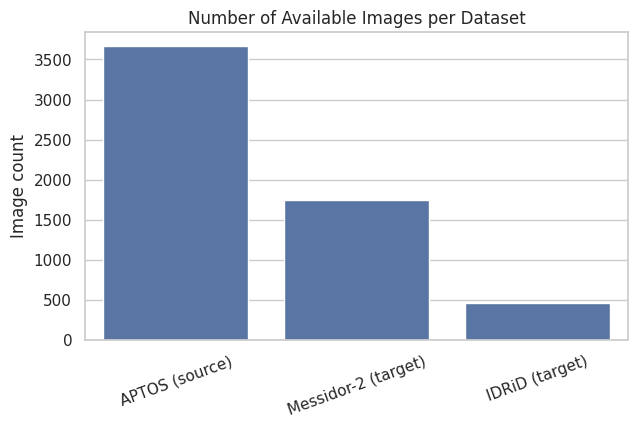

{'APTOS (source)': 3662, 'Messidor-2 (target)': 1744, 'IDRiD (target)': 455}


In [11]:
available_target_dfs_raw = {"Messidor-2": messidor_df, "IDRiD": idrid_df}
if BMRD_USABLE:
    available_target_dfs_raw["BMRD"] = bmrd_df

sizes = {"APTOS (source)": len(aptos_df)}
for name, df in available_target_dfs_raw.items():
    sizes[f"{name} (target)"] = len(df)

plt.figure(figsize=(7,4))
sns.barplot(x=list(sizes.keys()), y=list(sizes.values()))
plt.title("Number of Available Images per Dataset")
plt.ylabel("Image count")
plt.xticks(rotation=20)
plt.show()
print(sizes)

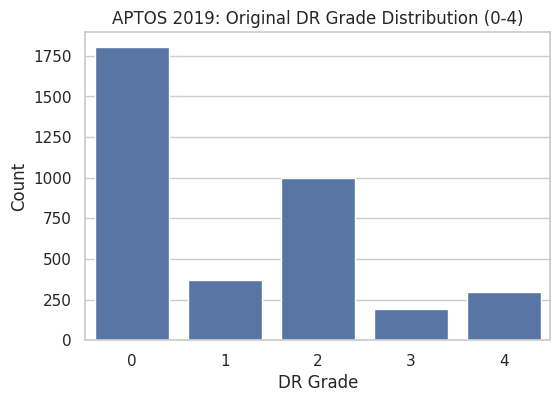

In [12]:
plt.figure(figsize=(6,4))
sns.countplot(x="diagnosis", data=aptos_df, order=sorted(aptos_df["diagnosis"].unique()))
plt.title("APTOS 2019: Original DR Grade Distribution (0-4)")
plt.xlabel("DR Grade"); plt.ylabel("Count")
plt.show()

## Binary label harmonization

Grades 0,1 -> Non-referable DR (0). Grades 2,3,4 -> Referable DR (1).
Applied identically to every dataset whose original labels are 0-4 ICDR grades.

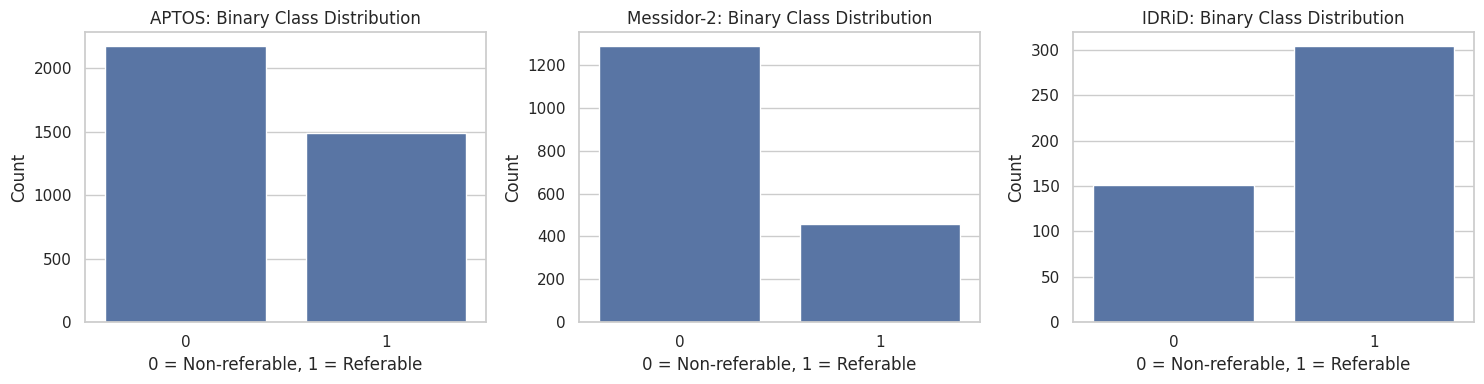

In [13]:
def harmonize_label(grade):
    return 0 if grade in [0, 1] else 1

aptos_df["diagnosis"] = aptos_df["diagnosis"].astype(int)
aptos_df["binary_label"] = aptos_df["diagnosis"].apply(harmonize_label)

for name, df in available_target_dfs_raw.items():
    if "binary_label" not in df.columns:
        df["diagnosis"] = df["diagnosis"].astype(int)
        df["binary_label"] = df["diagnosis"].apply(harmonize_label)

all_named_dfs = {"APTOS": aptos_df, **available_target_dfs_raw}
fig, axes = plt.subplots(1, len(all_named_dfs), figsize=(5*len(all_named_dfs), 4))
if len(all_named_dfs) == 1:
    axes = [axes]
for ax, (name, df) in zip(axes, all_named_dfs.items()):
    sns.countplot(x="binary_label", data=df, ax=ax)
    ax.set_title(f"{name}: Binary Class Distribution")
    ax.set_xlabel("0 = Non-referable, 1 = Referable"); ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

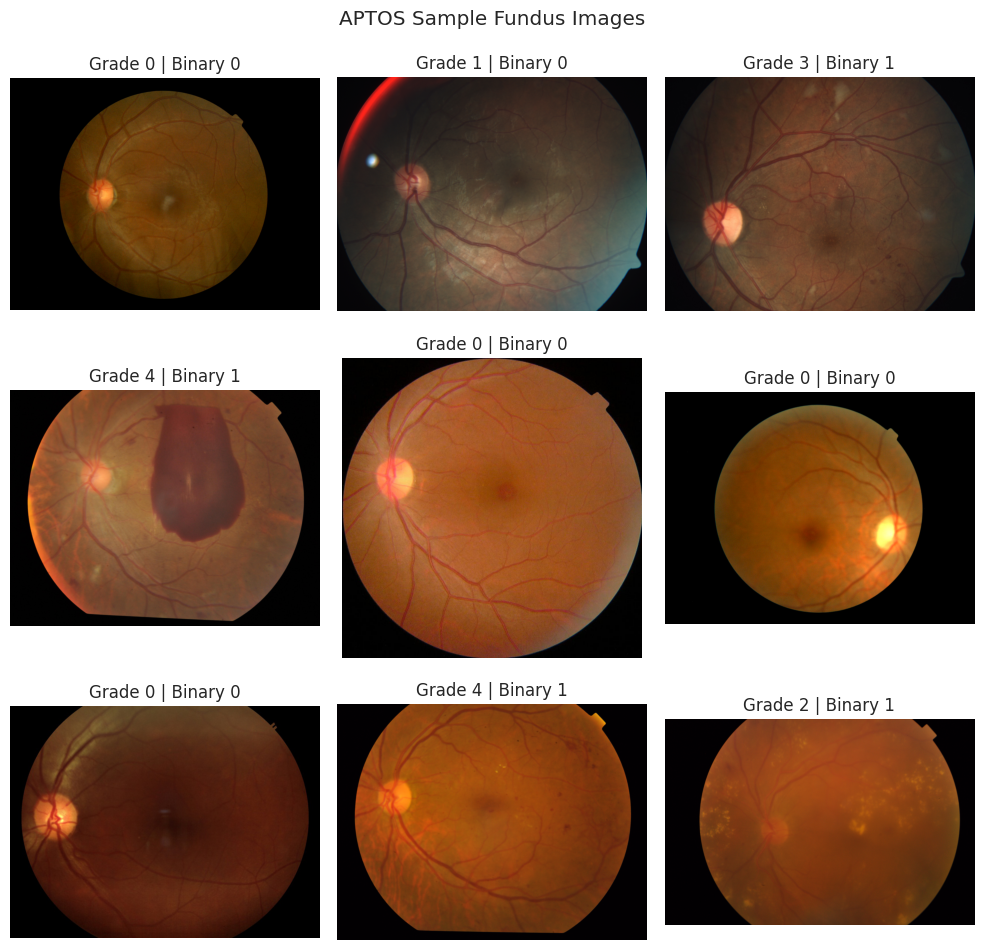

In [14]:
def load_rgb(path):
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

sample_rows = aptos_df.sample(9, random_state=SEED).reset_index(drop=True)
fig, axes = plt.subplots(3, 3, figsize=(10,10))
for i, ax in enumerate(axes.flat):
    row = sample_rows.loc[i]
    ax.imshow(load_rgb(row["img_path"]))
    ax.set_title(f"Grade {row['diagnosis']} | Binary {row['binary_label']}")
    ax.axis("off")
plt.suptitle("APTOS Sample Fundus Images")
plt.tight_layout()
plt.show()

Width  - mean: 2003.47 min: 474 max: 4288
Height - mean: 1525.22 min: 358 max: 2848


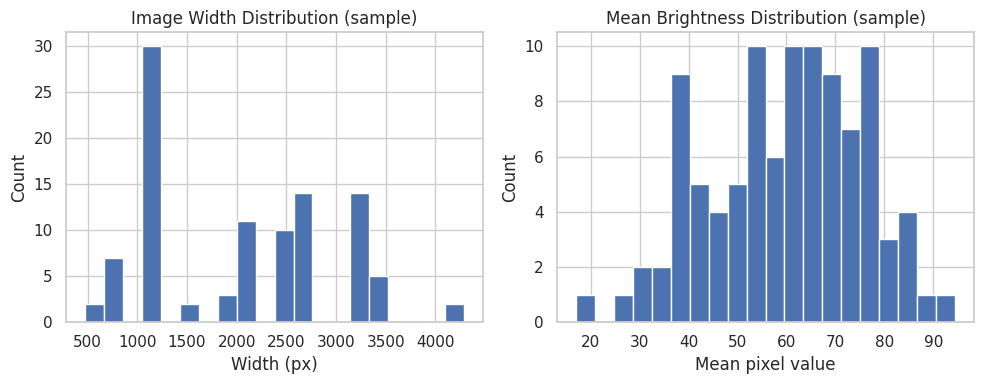

In [15]:
widths, heights, brightness = [], [], []
for p in aptos_df["img_path"].sample(100, random_state=SEED):
    img = load_rgb(p)
    widths.append(img.shape[1]); heights.append(img.shape[0]); brightness.append(img.mean())

print("Width  - mean:", np.mean(widths), "min:", min(widths), "max:", max(widths))
print("Height - mean:", np.mean(heights), "min:", min(heights), "max:", max(heights))

fig, axes = plt.subplots(1,2, figsize=(10,4))
axes[0].hist(widths, bins=20); axes[0].set_title("Image Width Distribution (sample)")
axes[0].set_xlabel("Width (px)"); axes[0].set_ylabel("Count")
axes[1].hist(brightness, bins=20); axes[1].set_title("Mean Brightness Distribution (sample)")
axes[1].set_xlabel("Mean pixel value"); axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

## Preprocessing

1. Crop black borders (simple intensity threshold bounding box).
2. Resize to 224x224.
3. ImageNet normalization.
4. Augmentation applied only to the APTOS training split.

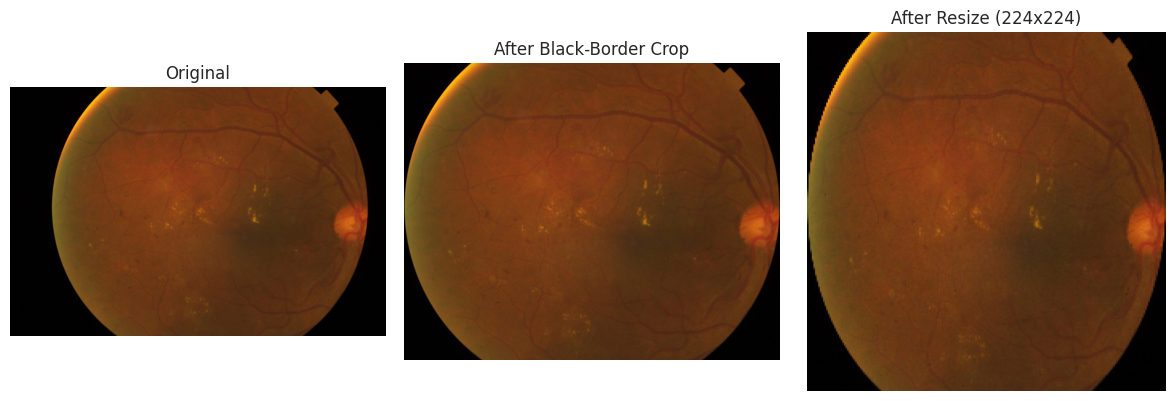

In [16]:
def crop_black_borders(img_rgb, tol=7):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    mask = gray > tol
    if mask.sum() == 0:
        return img_rgb
    coords = np.argwhere(mask)
    y0, x0 = coords.min(axis=0)
    y1, x1 = coords.max(axis=0) + 1
    return img_rgb[y0:y1, x0:x1]

def preprocess_image(img_rgb):
    cropped = crop_black_borders(img_rgb)
    resized = cv2.resize(cropped, (IMG_SIZE, IMG_SIZE))
    return cropped, resized

sample_path = aptos_df["img_path"].iloc[0]
orig = load_rgb(sample_path)
cropped, resized = preprocess_image(orig)

fig, axes = plt.subplots(1,3, figsize=(12,4))
axes[0].imshow(orig); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(cropped); axes[1].set_title("After Black-Border Crop"); axes[1].axis("off")
axes[2].imshow(resized); axes[2].set_title("After Resize (224x224)"); axes[2].axis("off")
plt.tight_layout()
plt.show()

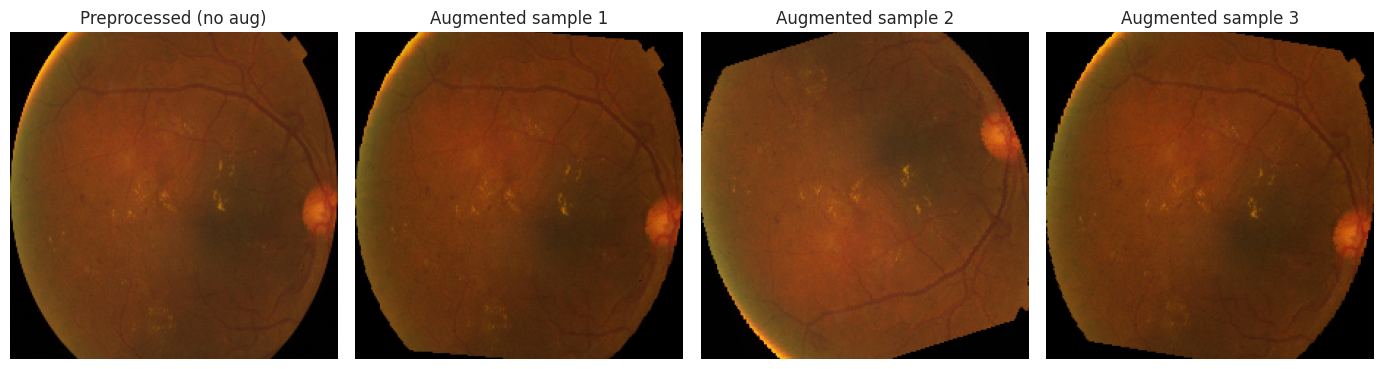

In [17]:
train_augment = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
])

pil_img = Image.fromarray(resized)
fig, axes = plt.subplots(1,4, figsize=(14,4))
axes[0].imshow(pil_img); axes[0].set_title("Preprocessed (no aug)"); axes[0].axis("off")
for i in range(1,4):
    aug_img = train_augment(pil_img)
    axes[i].imshow(aug_img); axes[i].set_title(f"Augmented sample {i}"); axes[i].axis("off")
plt.tight_layout()
plt.show()

## Split APTOS (80/10/10, stratified)

APTOS 2019 does not publish patient identifiers, so a patient-level split is not
possible. This is a documented limitation. An image-level stratified split on the
binary label is used instead.

In [18]:
train_df, temp_df = train_test_split(
    aptos_df, test_size=0.2, stratify=aptos_df["binary_label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df["binary_label"], random_state=SEED
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df), "Val:", len(val_df), "Source-test:", len(test_df))
for name, d in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(name, "binary distribution:\n", d["binary_label"].value_counts(normalize=True))

Train: 2929 Val: 366 Source-test: 367
Train binary distribution:
 binary_label
0    0.594059
1    0.405941
Name: proportion, dtype: float64
Val binary distribution:
 binary_label
0    0.592896
1    0.407104
Name: proportion, dtype: float64
Test binary distribution:
 binary_label
0    0.594005
1    0.405995
Name: proportion, dtype: float64


In [19]:
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
train_transform_full = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class DRDataset(Dataset):
    def __init__(self, df, train=False):
        self.df = df.reset_index(drop=True)
        self.train = train
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.loc[idx]
        img = load_rgb(row["img_path"])
        _, resized = preprocess_image(img)
        pil_img = Image.fromarray(resized)
        tf = train_transform_full if self.train else eval_transform
        tensor_img = tf(pil_img)
        label = int(row["binary_label"])
        return tensor_img, label

BATCH_SIZE = 32
NUM_WORKERS = 0  # 0 avoids multiprocessing worker-shutdown errors seen in Kaggle/Colab

train_ds = DRDataset(train_df, train=True)
val_ds   = DRDataset(val_df, train=False)
test_ds  = DRDataset(test_df, train=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

target_dfs = dict(available_target_dfs_raw)  # {"Messidor-2":..., "IDRiD":..., maybe "BMRD":...}
target_loaders = {
    name: DataLoader(DRDataset(df, train=False), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    for name, df in target_dfs.items()
}
print("Dataloaders ready. Target domains:", list(target_loaders.keys()))

Dataloaders ready. Target domains: ['Messidor-2', 'IDRiD']


## Model: MobileNetV3-Large (primary)

In [20]:
def build_mobilenet(dropout_p=0.3, pretrained=True):
    weights = models.MobileNet_V3_Large_Weights.DEFAULT if pretrained else None
    model = models.mobilenet_v3_large(weights=weights)
    in_features = model.classifier[3].in_features
    model.classifier[2] = nn.Dropout(p=dropout_p)
    model.classifier[3] = nn.Linear(in_features, 2)
    return model

mobilenet_model = build_mobilenet().to(DEVICE)
print(mobilenet_model.classifier)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 128MB/s] 


Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=1280, out_features=2, bias=True)
)


## Train the source model (APTOS only)

Weighted cross-entropy handles class imbalance. Early stopping uses validation loss.

In [21]:
def compute_class_weights(df):
    counts = df["binary_label"].value_counts().sort_index()
    total = counts.sum()
    weights = total / (2.0 * counts)
    return torch.tensor(weights.values, dtype=torch.float32)

def evaluate_loss_and_auc(model, loader, criterion, device):
    model.eval()
    total_loss, all_probs, all_labels = 0.0, [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = criterion(logits, y)
            total_loss += loss.item() * x.size(0)
            probs = torch.softmax(logits, dim=1)[:, 1]
            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(y.cpu().numpy())
    avg_loss = total_loss / len(loader.dataset)
    try:
        auc = roc_auc_score(all_labels, all_probs)
    except ValueError:
        auc = float("nan")
    return avg_loss, auc, np.array(all_labels), np.array(all_probs)

def train_source_model(model, train_loader, val_loader, train_df, device,
                        max_epochs=15, patience=4, lr=1e-4, ckpt_path="model.pt"):
    class_weights = compute_class_weights(train_df).to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "val_auc": []}
    best_val_loss = float("inf")
    epochs_no_improve = 0

    for epoch in range(max_epochs):
        model.train()
        running_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * x.size(0)
        train_loss = running_loss / len(train_loader.dataset)

        val_loss, val_auc, _, _ = evaluate_loss_and_auc(model, val_loader, criterion, device)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_auc"].append(val_auc)
        print(f"Epoch {epoch+1}/{max_epochs} | train_loss={train_loss:.4f} val_loss={val_loss:.4f} val_auc={val_auc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            epochs_no_improve = 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print("Early stopping triggered.")
                break

    model.load_state_dict(torch.load(ckpt_path))
    return model, history

In [22]:
mobilenet_model, mobilenet_history = train_source_model(
    mobilenet_model, train_loader, val_loader, train_df, DEVICE,
    max_epochs=5, patience=4, lr=1e-4, ckpt_path="mobilenet_source.pt"
)

Epoch 1/5 | train_loss=0.3217 val_loss=0.5429 val_auc=0.9699
Epoch 2/5 | train_loss=0.1825 val_loss=0.3485 val_auc=0.9805
Epoch 3/5 | train_loss=0.1651 val_loss=0.1953 val_auc=0.9819
Epoch 4/5 | train_loss=0.1422 val_loss=0.1835 val_auc=0.9807
Epoch 5/5 | train_loss=0.1413 val_loss=0.1791 val_auc=0.9814


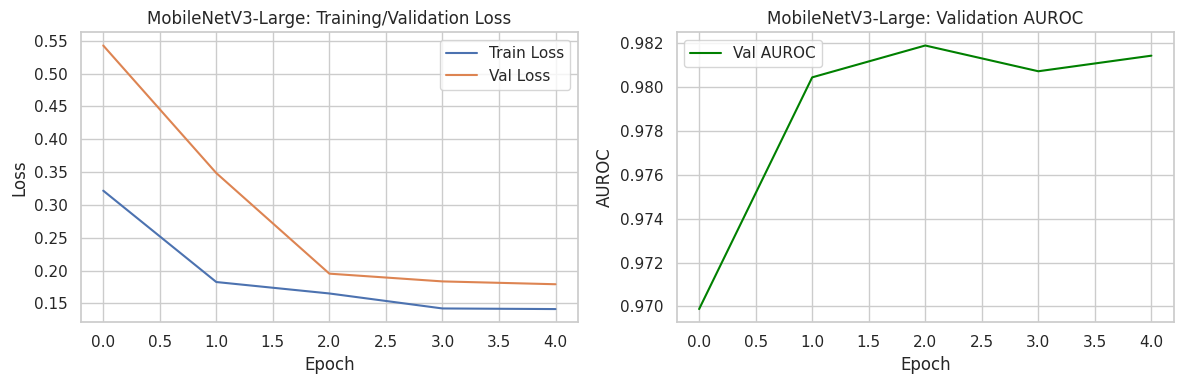

In [23]:
fig, axes = plt.subplots(1,2, figsize=(12,4))
axes[0].plot(mobilenet_history["train_loss"], label="Train Loss")
axes[0].plot(mobilenet_history["val_loss"], label="Val Loss")
axes[0].set_title("MobileNetV3-Large: Training/Validation Loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()

axes[1].plot(mobilenet_history["val_auc"], label="Val AUROC", color="green")
axes[1].set_title("MobileNetV3-Large: Validation AUROC")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("AUROC"); axes[1].legend()
plt.tight_layout()
plt.show()

## Comparison architecture: EfficientNet-B0

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 141MB/s] 


Epoch 1/5 | train_loss=0.3381 val_loss=0.1881 val_auc=0.9769
Epoch 2/5 | train_loss=0.1959 val_loss=0.1651 val_auc=0.9844
Epoch 3/5 | train_loss=0.1741 val_loss=0.1721 val_auc=0.9841
Epoch 4/5 | train_loss=0.1633 val_loss=0.1462 val_auc=0.9880
Epoch 5/5 | train_loss=0.1379 val_loss=0.1738 val_auc=0.9865


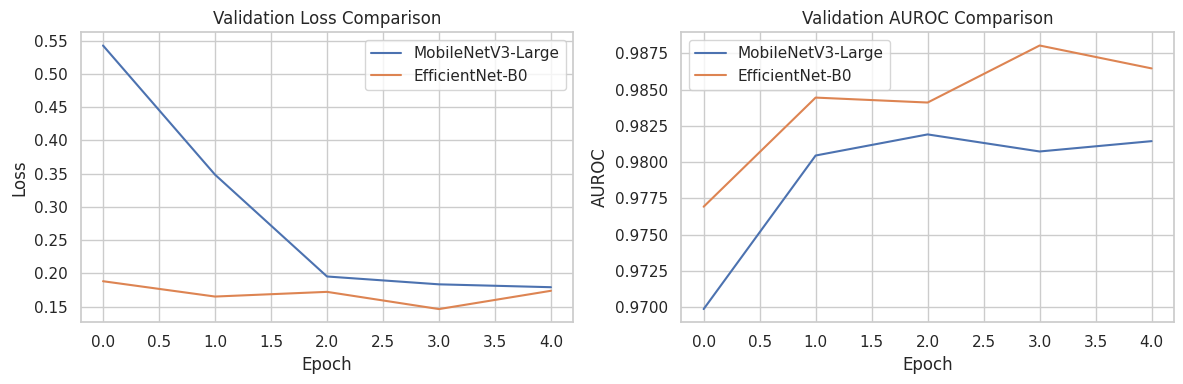

In [24]:
def build_efficientnet(dropout_p=0.3, pretrained=True):
    weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
    model = models.efficientnet_b0(weights=weights)
    in_features = model.classifier[1].in_features
    model.classifier[0] = nn.Dropout(p=dropout_p)
    model.classifier[1] = nn.Linear(in_features, 2)
    return model

efficientnet_model = build_efficientnet().to(DEVICE)
efficientnet_model, efficientnet_history = train_source_model(
    efficientnet_model, train_loader, val_loader, train_df, DEVICE,
    max_epochs=5, patience=4, lr=1e-4, ckpt_path="efficientnet_source.pt"
)

fig, axes = plt.subplots(1,2, figsize=(12,4))
axes[0].plot(mobilenet_history["val_loss"], label="MobileNetV3-Large")
axes[0].plot(efficientnet_history["val_loss"], label="EfficientNet-B0")
axes[0].set_title("Validation Loss Comparison"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()

axes[1].plot(mobilenet_history["val_auc"], label="MobileNetV3-Large")
axes[1].plot(efficientnet_history["val_auc"], label="EfficientNet-B0")
axes[1].set_title("Validation AUROC Comparison"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("AUROC"); axes[1].legend()
plt.tight_layout()
plt.show()

## Metric utilities and decision threshold (from APTOS validation only)

In [25]:
def get_probs_labels(model, loader, device):
    model.eval()
    probs_all, labels_all = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            logits = model(x)
            probs = torch.softmax(logits, dim=1)[:, 1]
            probs_all.extend(probs.cpu().numpy())
            labels_all.extend(y.numpy())
    return np.array(labels_all), np.array(probs_all)

def expected_calibration_error(labels, probs, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        mask = (probs >= bins[i]) & (probs < bins[i+1])
        if mask.sum() == 0:
            continue
        acc = labels[mask].mean()
        conf = probs[mask].mean()
        ece += (mask.sum() / len(probs)) * abs(acc - conf)
    return ece

def compute_metrics(labels, probs, threshold=0.5):
    preds = (probs >= threshold).astype(int)
    try:
        auc = roc_auc_score(labels, probs)
    except ValueError:
        auc = float("nan")
    tn, fp, fn, tp = confusion_matrix(labels, preds, labels=[0,1]).ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float("nan")
    f1 = f1_score(labels, preds, zero_division=0)
    brier = np.mean((probs - labels) ** 2)
    ece = expected_calibration_error(labels, probs)
    return {"AUROC": auc, "Sensitivity": sensitivity, "Specificity": specificity,
            "F1": f1, "ECE": ece, "Brier": brier}

def find_best_threshold(labels, probs):
    thresholds = np.linspace(0.05, 0.95, 19)
    best_t, best_f1 = 0.5, -1
    for t in thresholds:
        preds = (probs >= t).astype(int)
        f1 = f1_score(labels, preds, zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    return best_t

val_labels, val_probs = get_probs_labels(mobilenet_model, val_loader, DEVICE)
DECISION_THRESHOLD = find_best_threshold(val_labels, val_probs)
print("Decision threshold chosen from APTOS validation set:", round(DECISION_THRESHOLD, 4))

Decision threshold chosen from APTOS validation set: 0.6


## Source-only evaluation across domains (before adaptation)

In [26]:
def evaluate_dataset(model, loader, threshold, name):
    labels, probs = get_probs_labels(model, loader, DEVICE)
    metrics = compute_metrics(labels, probs, threshold)
    print(f"{name}: {metrics}")
    return metrics, labels, probs

source_only_results = {}
source_eval_cache = {}
m, l, p = evaluate_dataset(mobilenet_model, test_loader, DECISION_THRESHOLD, "APTOS source test")
source_only_results["APTOS (source test)"] = m
source_eval_cache["APTOS (source test)"] = (l, p)

for name, loader in target_loaders.items():
    m, l, p = evaluate_dataset(mobilenet_model, loader, DECISION_THRESHOLD, name)
    source_only_results[name] = m
    source_eval_cache[name] = (l, p)

source_only_df = pd.DataFrame(source_only_results).T
source_only_df

APTOS source test: {'AUROC': np.float64(0.9827904685672064), 'Sensitivity': np.float64(0.9463087248322147), 'Specificity': np.float64(0.9174311926605505), 'F1': 0.9155844155844156, 'ECE': np.float64(0.04988953848851575), 'Brier': np.float64(0.05425638134094441)}
Messidor-2: {'AUROC': np.float64(0.7607432684019118), 'Sensitivity': np.float64(0.3150984682713348), 'Specificity': np.float64(0.9595959595959596), 'F1': 0.44104134762633995, 'ECE': np.float64(0.17715198432795973), 'Brier': np.float64(0.18569265586520906)}
IDRiD: {'AUROC': np.float64(0.9570843499477172), 'Sensitivity': np.float64(0.7730263157894737), 'Specificity': np.float64(0.9735099337748344), 'F1': 0.8655616942909761, 'ECE': np.float64(0.12182067344272204), 'Brier': np.float64(0.10641690975116698)}


,AUROC,Sensitivity,Specificity,F1,ECE,Brier
APTOS (source test),0.982790,0.946309,0.917431,0.915584,0.049890,0.054256
Messidor-2,0.760743,0.315098,0.959596,0.441041,0.177152,0.185693
IDRiD,0.957084,0.773026,0.973510,0.865562,0.121821,0.106417


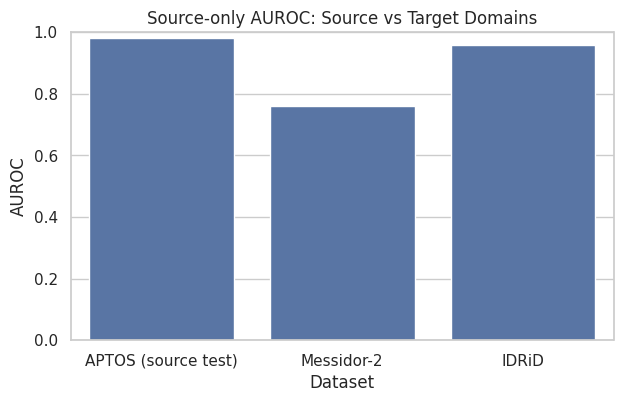

In [27]:
plt.figure(figsize=(7,4))
sns.barplot(x=source_only_df.index, y=source_only_df["AUROC"])
plt.title("Source-only AUROC: Source vs Target Domains")
plt.ylabel("AUROC"); plt.xlabel("Dataset")
plt.ylim(0,1)
plt.show()

## Uncertainty estimation: prediction entropy and MC-Dropout

In [28]:
def binary_entropy(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

def enable_dropout(model):
    for m in model.modules():
        if isinstance(m, nn.Dropout):
            m.train()

def mc_dropout_predict(model, loader, device, n_passes=10):
    model.eval()
    enable_dropout(model)
    all_probs_passes = []
    labels_all = None
    with torch.no_grad():
        for _ in range(n_passes):
            probs_batch, labels_batch = [], []
            for x, y in loader:
                x = x.to(device)
                logits = model(x)
                probs = torch.softmax(logits, dim=1)[:, 1]
                probs_batch.extend(probs.cpu().numpy())
                labels_batch.extend(y.numpy())
            all_probs_passes.append(probs_batch)
            if labels_all is None:
                labels_all = labels_batch
    all_probs_passes = np.array(all_probs_passes)
    return np.array(labels_all), all_probs_passes.mean(axis=0), all_probs_passes.std(axis=0)

val_mc_labels, val_mc_mean, val_mc_std = mc_dropout_predict(mobilenet_model, val_loader, DEVICE, n_passes=10)
val_entropy = binary_entropy(val_probs)
print("Val entropy sample:", val_entropy[:5])
print("Val MC-dropout std sample:", val_mc_std[:5])

Val entropy sample: [5.9694488e-05 1.4552298e-01 4.6821270e-02 3.6287898e-01 6.3232571e-02]
Val MC-dropout std sample: [1.7338866e-06 4.5404304e-03 1.0177873e-03 1.1135392e-02 2.1729833e-03]


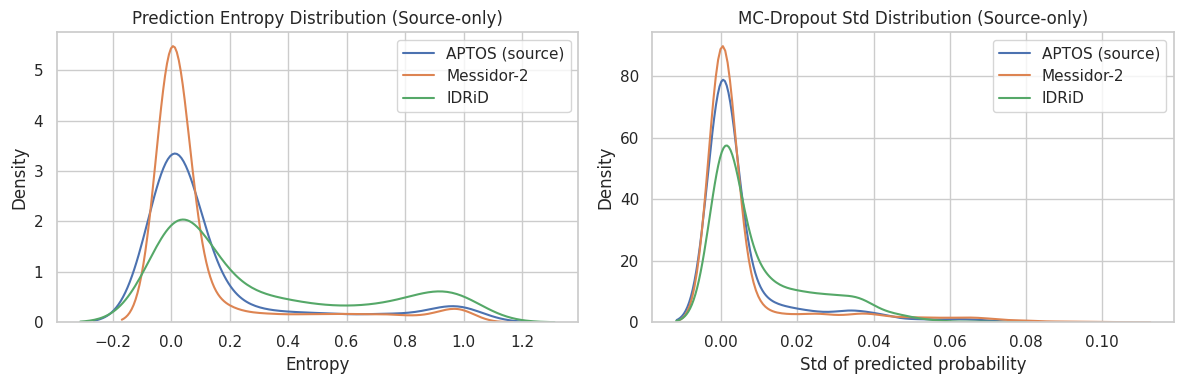

In [29]:
target_entropy = {}
target_mc_std = {}
for name, loader in target_loaders.items():
    labels_t, probs_t = source_eval_cache[name]
    target_entropy[name] = binary_entropy(probs_t)
    _, _, mc_std_t = mc_dropout_predict(mobilenet_model, loader, DEVICE, n_passes=10)
    target_mc_std[name] = mc_std_t

fig, axes = plt.subplots(1,2, figsize=(12,4))
sns.kdeplot(val_entropy, label="APTOS (source)", ax=axes[0])
for name, ent in target_entropy.items():
    sns.kdeplot(ent, label=name, ax=axes[0])
axes[0].set_title("Prediction Entropy Distribution (Source-only)")
axes[0].set_xlabel("Entropy"); axes[0].legend()

sns.kdeplot(val_mc_std, label="APTOS (source)", ax=axes[1])
for name, std in target_mc_std.items():
    sns.kdeplot(std, label=name, ax=axes[1])
axes[1].set_title("MC-Dropout Std Distribution (Source-only)")
axes[1].set_xlabel("Std of predicted probability"); axes[1].legend()
plt.tight_layout()
plt.show()

## UA-TTA thresholds (APTOS validation only, never target labels)

Entropy and MC-Dropout std thresholds are the median values on APTOS validation.
The selective-prediction referral threshold is the 75th percentile of validation entropy.

In [30]:
ENTROPY_THRESHOLD = float(np.median(val_entropy))
MC_STD_THRESHOLD = float(np.median(val_mc_std))
REFERRAL_ENTROPY_THRESHOLD = float(np.percentile(val_entropy, 75))

print("UA-TTA entropy threshold (median, val):", round(ENTROPY_THRESHOLD, 4))
print("UA-TTA MC-dropout std threshold (median, val):", round(MC_STD_THRESHOLD, 4))
print("Selective-prediction referral threshold (75th pct, val):", round(REFERRAL_ENTROPY_THRESHOLD, 4))

UA-TTA entropy threshold (median, val): 0.0037
UA-TTA MC-dropout std threshold (median, val): 0.0001
Selective-prediction referral threshold (75th pct, val): 0.1076


## BN-Adapt baseline

Recompute BatchNorm statistics using unlabeled target images only, with
`momentum=None` so PyTorch accumulates a true cumulative average over the
whole target set instead of an exponential moving average biased toward the
last few batches.

In [31]:
def bn_adapt(model, loader, device):
    model = copy.deepcopy(model)
    model.train()
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.reset_running_stats()
            m.momentum = None
    with torch.no_grad():
        for x, _ in loader:
            x = x.to(device)
            model(x)
    model.eval()
    return model

## Tent baseline: entropy minimization, BatchNorm affine update, no sample filtering

In [32]:
def freeze_except_bn_affine(model):
    for p in model.parameters():
        p.requires_grad = False
    bn_params = []
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.weight.requires_grad = True
            m.bias.requires_grad = True
            bn_params += [m.weight, m.bias]
    return bn_params

def tent_adapt(model, loader, device, lr=1e-3):
    model = copy.deepcopy(model)
    bn_params = freeze_except_bn_affine(model)
    optimizer = torch.optim.Adam(bn_params, lr=lr)
    model.train()
    for x, _ in loader:
        x = x.to(device)
        logits = model(x)
        probs = torch.softmax(logits, dim=1)
        entropy_loss = -(probs * torch.log(probs + 1e-8)).sum(dim=1).mean()
        optimizer.zero_grad()
        entropy_loss.backward()
        optimizer.step()
    model.eval()
    return model

## Proposed UA-TTA: uncertainty-filtered BatchNorm adaptation with collapse detection

In [33]:
def ua_tta_adapt(model, loader, device, entropy_thr, mcstd_thr,
                  mc_passes=10, lr=1e-3, collapse_bound=0.97):
    model = copy.deepcopy(model)
    bn_params = freeze_except_bn_affine(model)
    optimizer = torch.optim.Adam(bn_params, lr=lr)
    prev_state = copy.deepcopy(model.state_dict())
    collapsed = False
    n_used_total, n_seen_total = 0, 0

    for x, _ in loader:
        x = x.to(device)
        n_seen_total += x.size(0)

        model.eval()
        with torch.no_grad():
            logits = model(x)
            probs = torch.softmax(logits, dim=1)[:, 1]
            ent = torch.tensor(binary_entropy(probs.cpu().numpy())).to(device)

        enable_dropout(model)
        mc_probs = []
        with torch.no_grad():
            for _ in range(mc_passes):
                logits_mc = model(x)
                p = torch.softmax(logits_mc, dim=1)[:, 1]
                mc_probs.append(p.unsqueeze(0))
        mc_probs = torch.cat(mc_probs, dim=0)
        mc_std = mc_probs.std(dim=0)

        reliable_mask = (ent < entropy_thr) & (mc_std < mcstd_thr)
        if reliable_mask.sum().item() == 0:
            continue
        x_sel = x[reliable_mask]
        n_used_total += x_sel.size(0)

        model.train()
        for m in model.modules():
            if isinstance(m, nn.Dropout):
                m.eval()
        logits_sel = model(x_sel)
        probs_sel = torch.softmax(logits_sel, dim=1)
        entropy_loss = -(probs_sel * torch.log(probs_sel + 1e-8)).sum(dim=1).mean()
        optimizer.zero_grad()
        entropy_loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            preds_check = model(x).argmax(dim=1).float()
        pos_rate = preds_check.mean().item()
        if pos_rate > collapse_bound or pos_rate < (1 - collapse_bound):
            model.load_state_dict(prev_state)
            collapsed = True
            break
        else:
            prev_state = copy.deepcopy(model.state_dict())

    model.eval()
    print(f"UA-TTA used {n_used_total}/{n_seen_total} images for adaptation. Collapse detected: {collapsed}")
    return model, collapsed

## Run all four methods on each target dataset

Each method starts from the same frozen source checkpoint so baselines never
influence each other.

In [34]:
def load_fresh_source_model(ckpt_path="mobilenet_source.pt"):
    m = build_mobilenet().to(DEVICE)
    m.load_state_dict(torch.load(ckpt_path))
    m.eval()
    return m

adapted_models = {}
all_results = []

for dname, loader in target_loaders.items():
    adapted_models[dname] = {}

    src_model = load_fresh_source_model()
    labels, probs = get_probs_labels(src_model, loader, DEVICE)
    m = compute_metrics(labels, probs, DECISION_THRESHOLD)
    m.update({"Dataset": dname, "Method": "Source-only"})
    all_results.append(m)
    adapted_models[dname]["Source-only"] = src_model

    bn_model = bn_adapt(load_fresh_source_model(), loader, DEVICE)
    labels, probs = get_probs_labels(bn_model, loader, DEVICE)
    m = compute_metrics(labels, probs, DECISION_THRESHOLD)
    m.update({"Dataset": dname, "Method": "BN-Adapt"})
    all_results.append(m)
    adapted_models[dname]["BN-Adapt"] = bn_model

    tent_model = tent_adapt(load_fresh_source_model(), loader, DEVICE, lr=1e-3)
    labels, probs = get_probs_labels(tent_model, loader, DEVICE)
    m = compute_metrics(labels, probs, DECISION_THRESHOLD)
    m.update({"Dataset": dname, "Method": "Tent"})
    all_results.append(m)
    adapted_models[dname]["Tent"] = tent_model

    uatta_model, collapsed = ua_tta_adapt(
        load_fresh_source_model(), loader, DEVICE, ENTROPY_THRESHOLD, MC_STD_THRESHOLD, mc_passes=10, lr=1e-3
    )
    labels, probs = get_probs_labels(uatta_model, loader, DEVICE)
    m = compute_metrics(labels, probs, DECISION_THRESHOLD)
    m.update({"Dataset": dname, "Method": "UA-TTA"})
    all_results.append(m)
    adapted_models[dname]["UA-TTA"] = uatta_model
    torch.save(uatta_model.state_dict(), f"uatta_{dname.replace('-','').lower()}.pt")

results_df = pd.DataFrame(all_results)[["Dataset", "Method", "AUROC", "Sensitivity", "Specificity", "F1", "ECE", "Brier"]]
results_df

UA-TTA used 89/160 images for adaptation. Collapse detected: True
UA-TTA used 93/455 images for adaptation. Collapse detected: False


,Dataset,Method,AUROC,Sensitivity,Specificity,F1,ECE,Brier
0,Messidor-2,Source-only,0.760743,0.315098,0.959596,0.441041,0.177152,0.185693
1,Messidor-2,BN-Adapt,0.756408,0.490153,0.877234,0.533969,0.165478,0.191510
2,Messidor-2,Tent,0.749784,0.245077,0.979021,0.375839,0.198967,0.203524
3,Messidor-2,UA-TTA,0.760303,0.286652,0.970474,0.418530,0.182831,0.189835
4,IDRiD,Source-only,0.957084,0.773026,0.973510,0.865562,0.121821,0.106417
5,IDRiD,BN-Adapt,0.960897,0.585526,1.000000,0.738589,0.246849,0.192563
6,IDRiD,Tent,0.956191,0.641447,0.993377,0.780000,0.214227,0.177116
7,IDRiD,UA-TTA,0.957825,0.661184,0.993377,0.794466,0.203703,0.161329


## Bootstrap 95% confidence intervals

In [35]:
def bootstrap_metric(labels, probs, threshold, n_boot=1000, seed=SEED):
    rng = np.random.RandomState(seed)
    n = len(labels)
    auc_list, sens_list, spec_list, f1_list = [], [], [], []
    for _ in range(n_boot):
        idx = rng.choice(n, n, replace=True)
        bl, bp = labels[idx], probs[idx]
        if len(np.unique(bl)) < 2:
            continue
        m = compute_metrics(bl, bp, threshold)
        auc_list.append(m["AUROC"]); sens_list.append(m["Sensitivity"])
        spec_list.append(m["Specificity"]); f1_list.append(m["F1"])

    def ci(values):
        values = np.array(values)
        values = values[~np.isnan(values)]
        return (float("nan"), float("nan")) if len(values) == 0 else (np.percentile(values, 2.5), np.percentile(values, 97.5))

    return {"AUROC_CI": ci(auc_list), "Sensitivity_CI": ci(sens_list),
            "Specificity_CI": ci(spec_list), "F1_CI": ci(f1_list)}

ci_rows = []
for dname, loader in target_loaders.items():
    for method, model in adapted_models[dname].items():
        labels, probs = get_probs_labels(model, loader, DEVICE)
        ci_result = bootstrap_metric(labels, probs, DECISION_THRESHOLD, n_boot=1000, seed=SEED)
        ci_result.update({"Dataset": dname, "Method": method})
        ci_rows.append(ci_result)

ci_df = pd.DataFrame(ci_rows)
ci_df

,AUROC_CI,Sensitivity_CI,Specificity_CI,F1_CI,Dataset,Method
0,"(0.7312816662738805, 0.7866228074132345)","(0.27213477321814256, 0.35733420115100023)","(0.9485506790612013, 0.9698854833585847)","(0.3909712194393268, 0.48523447326997643)",Messidor-2,Source-only
1,"(0.727779478414248, 0.7824296021129026)","(0.44060215892540705, 0.5326491228070176)","(0.8580185543840974, 0.8951527655516432)","(0.4887700251194613, 0.5714285714285714)",Messidor-2,BN-Adapt
2,"(0.7191157866625846, 0.7769361483938148)","(0.20134512768390295, 0.2828549817203849)","(0.9706778793863415, 0.9857951637943746)","(0.3194162129461585, 0.4234629958222327)",Messidor-2,Tent
3,"(0.7304372284600418, 0.7868045387799804)","(0.24041709626019306, 0.3283293228222026)","(0.9612988096095231, 0.9790559561001764)","(0.3623433850367483, 0.46429147465437787)",Messidor-2,UA-TTA
4,"(0.9386639944772835, 0.973469131109468)","(0.7269402110859551, 0.8197293935241942)","(0.9454483188044832, 0.994012867122897)","(0.8336671385824486, 0.8945546995377504)",IDRiD,Source-only
5,"(0.9435859085043428, 0.975439762326424)","(0.5310174066321471, 0.6363715004718464)","(1.0, 1.0)","(0.6936791175308921, 0.7777836504580691)",IDRiD,BN-Adapt
6,"(0.9367978129680379, 0.971958202690993)","(0.5867988782051282, 0.6930945479416362)","(0.9772595137420719, 1.0)","(0.7385875551800963, 0.8171248270431838)",IDRiD,Tent
7,"(0.9395109039354074, 0.9738108892508873)","(0.6085286892071952, 0.7147653889619225)","(0.9772595137420719, 1.0)","(0.7550999918039505, 0.832)",IDRiD,UA-TTA


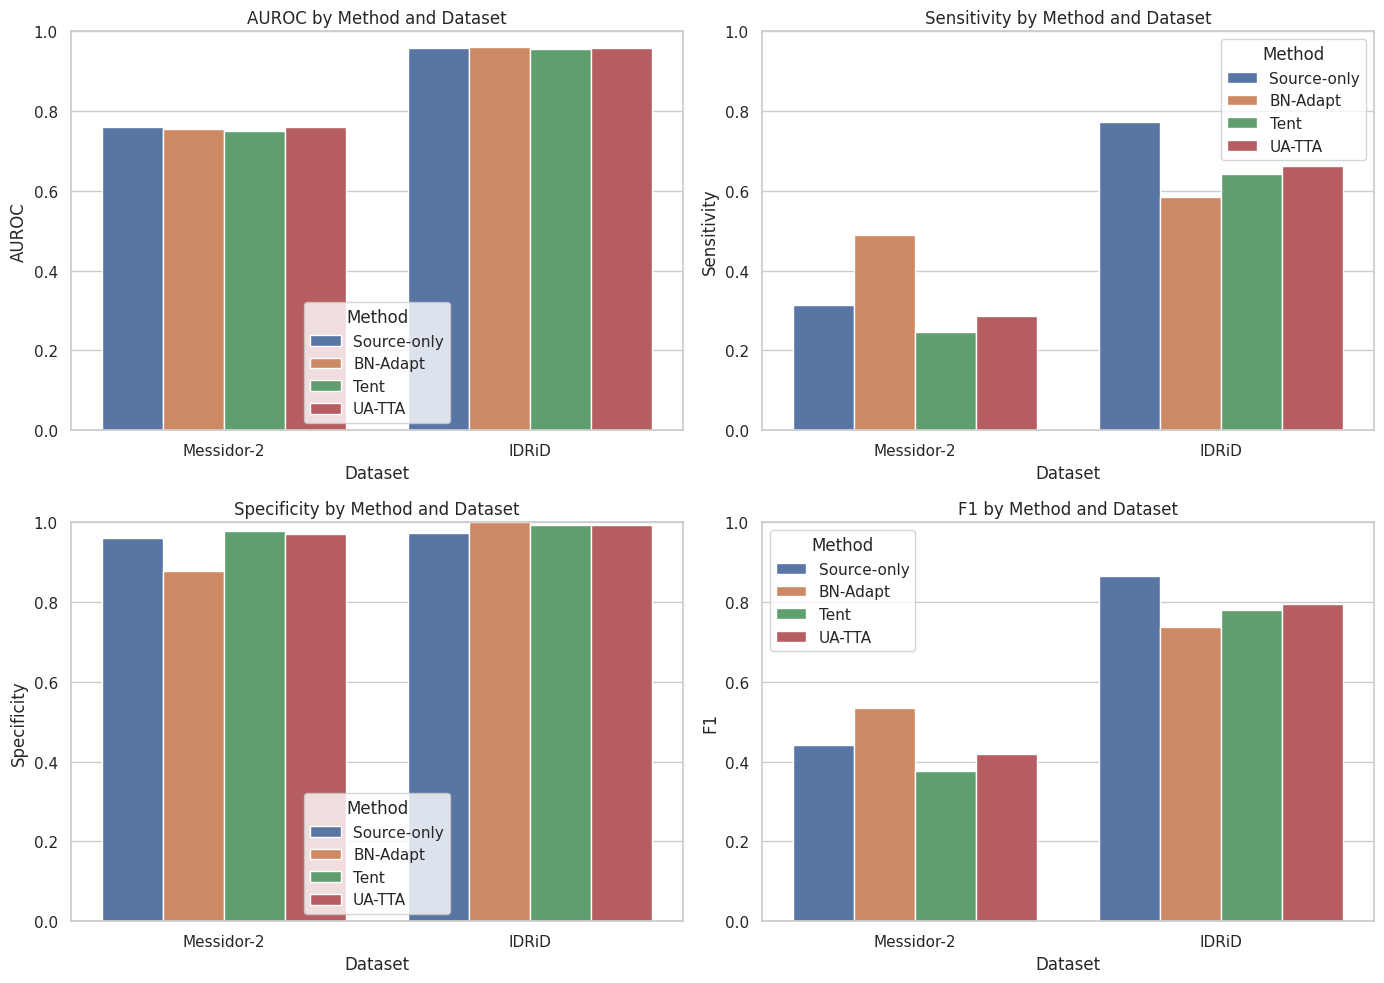

In [36]:
fig, axes = plt.subplots(2,2, figsize=(14,10))
for ax, metric in zip(axes.flat, ["AUROC", "Sensitivity", "Specificity", "F1"]):
    sns.barplot(data=results_df, x="Dataset", y=metric, hue="Method", ax=ax)
    ax.set_title(f"{metric} by Method and Dataset")
    ax.set_ylim(0,1)
plt.tight_layout()
plt.show()

## Calibration plots and risk-coverage curves

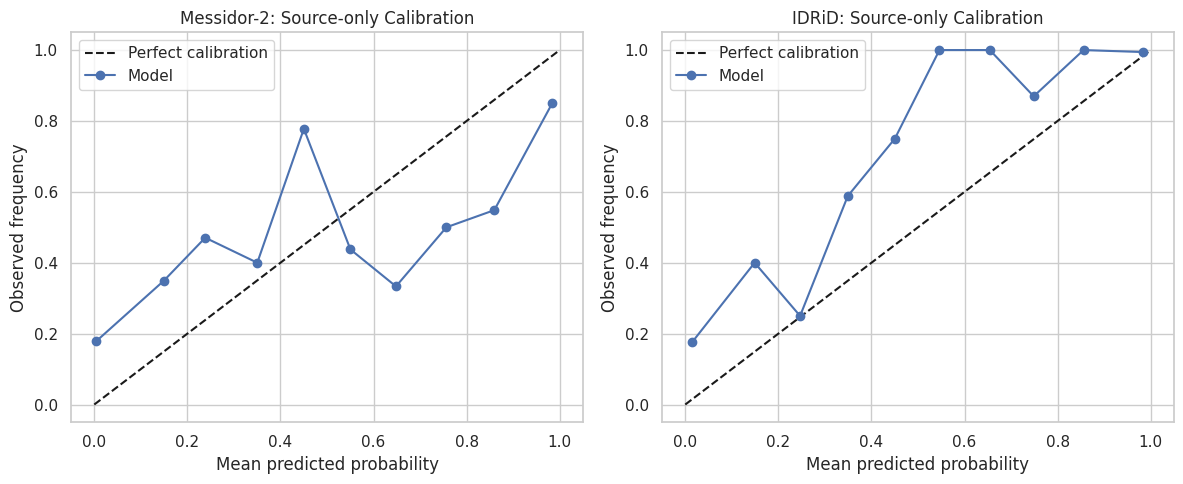

In [37]:
def reliability_diagram(labels, probs, ax, title, n_bins=10):
    bins = np.linspace(0,1,n_bins+1)
    accs, confs = [], []
    for i in range(n_bins):
        mask = (probs >= bins[i]) & (probs < bins[i+1])
        if mask.sum() == 0:
            continue
        accs.append(labels[mask].mean())
        confs.append(probs[mask].mean())
    ax.plot([0,1],[0,1],"k--", label="Perfect calibration")
    ax.plot(confs, accs, marker="o", label="Model")
    ax.set_title(title); ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Observed frequency"); ax.legend()

fig, axes = plt.subplots(1, len(target_loaders), figsize=(6*len(target_loaders), 5))
if len(target_loaders) == 1:
    axes = [axes]
for ax, dname in zip(axes, target_loaders.keys()):
    labels_src, probs_src = get_probs_labels(adapted_models[dname]["Source-only"], target_loaders[dname], DEVICE)
    reliability_diagram(labels_src, probs_src, ax, f"{dname}: Source-only Calibration")
plt.tight_layout()
plt.show()

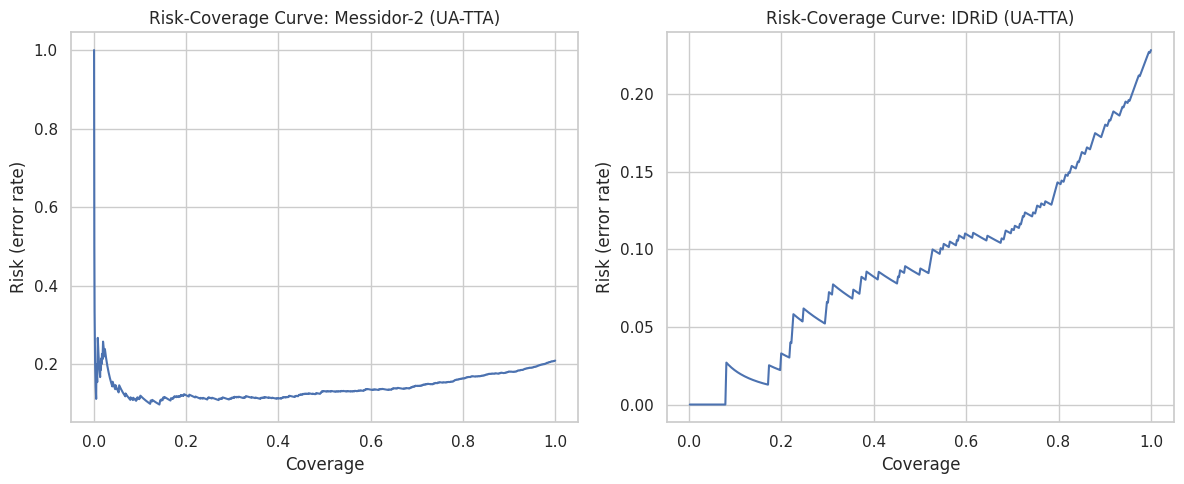

Messidor-2: operating-point coverage=0.830, risk=0.169
IDRiD: operating-point coverage=0.521, risk=0.089


In [38]:
def risk_coverage_curve(labels, probs, entropy_values, threshold):
    order = np.argsort(entropy_values)
    sorted_labels = labels[order]
    sorted_probs = probs[order]
    n = len(labels)
    coverages, risks = [], []
    for k in range(1, n+1):
        preds = (sorted_probs[:k] >= threshold).astype(int)
        risks.append(np.mean(preds != sorted_labels[:k]))
        coverages.append(k/n)
    return np.array(coverages), np.array(risks)

fig, axes = plt.subplots(1, len(target_loaders), figsize=(6*len(target_loaders), 5))
if len(target_loaders) == 1:
    axes = [axes]
for ax, dname in zip(axes, target_loaders.keys()):
    labels, probs = get_probs_labels(adapted_models[dname]["UA-TTA"], target_loaders[dname], DEVICE)
    entropy_vals = binary_entropy(probs)
    cov, risk = risk_coverage_curve(labels, probs, entropy_vals, DECISION_THRESHOLD)
    ax.plot(cov, risk)
    ax.set_title(f"Risk-Coverage Curve: {dname} (UA-TTA)")
    ax.set_xlabel("Coverage"); ax.set_ylabel("Risk (error rate)")
plt.tight_layout()
plt.show()

def selective_predict(prob, entropy_value, referral_threshold, decision_threshold):
    if entropy_value > referral_threshold:
        return "Uncertain. Please consult an ophthalmologist."
    return "Referable DR" if prob >= decision_threshold else "Non-referable DR"

for dname in target_loaders.keys():
    labels, probs = get_probs_labels(adapted_models[dname]["UA-TTA"], target_loaders[dname], DEVICE)
    entropy_vals = binary_entropy(probs)
    covered_mask = entropy_vals <= REFERRAL_ENTROPY_THRESHOLD
    coverage = covered_mask.mean()
    preds = (probs[covered_mask] >= DECISION_THRESHOLD).astype(int)
    risk = np.mean(preds != labels[covered_mask]) if covered_mask.sum() > 0 else float("nan")
    print(f"{dname}: operating-point coverage={coverage:.3f}, risk={risk:.3f}")

## Ablation studies

1. Filter type: no filter / entropy-only / entropy+MC-Dropout (UA-TTA).
2. Batch size: 8, 16, 32.
3. Architecture: MobileNetV3-Large vs EfficientNet-B0.

UA-TTA used 89/160 images for adaptation. Collapse detected: True
UA-TTA used 92/455 images for adaptation. Collapse detected: False


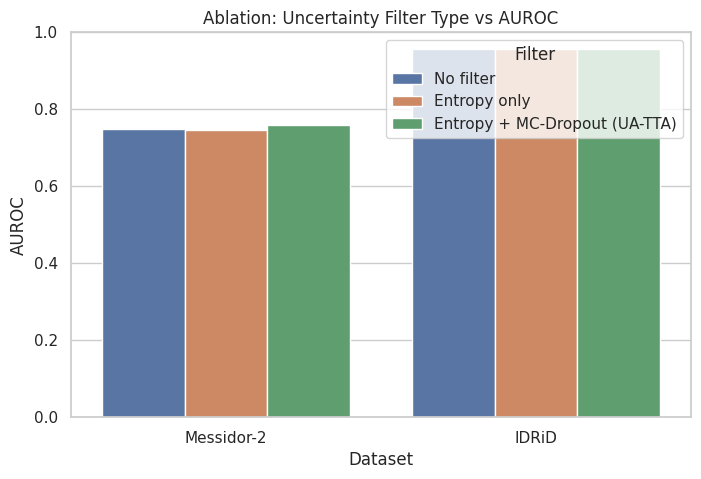

In [39]:
DEBUG_MODE = False  # set True for a quick, smaller run first

def no_filter_adapt(model, loader, device, lr=1e-3):
    return tent_adapt(model, loader, device, lr=lr)

def entropy_only_adapt(model, loader, device, entropy_thr, lr=1e-3):
    model = copy.deepcopy(model)
    bn_params = freeze_except_bn_affine(model)
    optimizer = torch.optim.Adam(bn_params, lr=lr)
    for x, _ in loader:
        x = x.to(device)
        model.eval()
        with torch.no_grad():
            probs = torch.softmax(model(x), dim=1)[:, 1]
            ent = binary_entropy(probs.cpu().numpy())
        mask = torch.tensor(ent < entropy_thr).to(device)
        if mask.sum().item() == 0:
            continue
        x_sel = x[mask]
        model.train()
        probs_sel = torch.softmax(model(x_sel), dim=1)
        loss = -(probs_sel * torch.log(probs_sel + 1e-8)).sum(dim=1).mean()
        optimizer.zero_grad(); loss.backward(); optimizer.step()
    model.eval()
    return model

ablation_filter_rows = []
targets_for_ablation = target_loaders if not DEBUG_MODE else dict(list(target_loaders.items())[:1])

for dname, loader in targets_for_ablation.items():
    base = load_fresh_source_model()
    for filt_name, fn in [
        ("No filter", lambda m: no_filter_adapt(copy.deepcopy(m), loader, DEVICE)),
        ("Entropy only", lambda m: entropy_only_adapt(copy.deepcopy(m), loader, DEVICE, ENTROPY_THRESHOLD)),
        ("Entropy + MC-Dropout (UA-TTA)", lambda m: ua_tta_adapt(copy.deepcopy(m), loader, DEVICE, ENTROPY_THRESHOLD, MC_STD_THRESHOLD)[0]),
    ]:
        adapted = fn(base)
        labels, probs = get_probs_labels(adapted, loader, DEVICE)
        r = compute_metrics(labels, probs, DECISION_THRESHOLD)
        r.update({"Dataset": dname, "Filter": filt_name})
        ablation_filter_rows.append(r)

ablation_filter_df = pd.DataFrame(ablation_filter_rows)
ablation_filter_df

plt.figure(figsize=(8,5))
sns.barplot(data=ablation_filter_df, x="Dataset", y="AUROC", hue="Filter")
plt.title("Ablation: Uncertainty Filter Type vs AUROC")
plt.ylim(0,1)
plt.show()

UA-TTA used 6/8 images for adaptation. Collapse detected: True
UA-TTA used 14/16 images for adaptation. Collapse detected: True
UA-TTA used 90/160 images for adaptation. Collapse detected: True
UA-TTA used 7/32 images for adaptation. Collapse detected: True
UA-TTA used 33/192 images for adaptation. Collapse detected: True
UA-TTA used 95/455 images for adaptation. Collapse detected: False


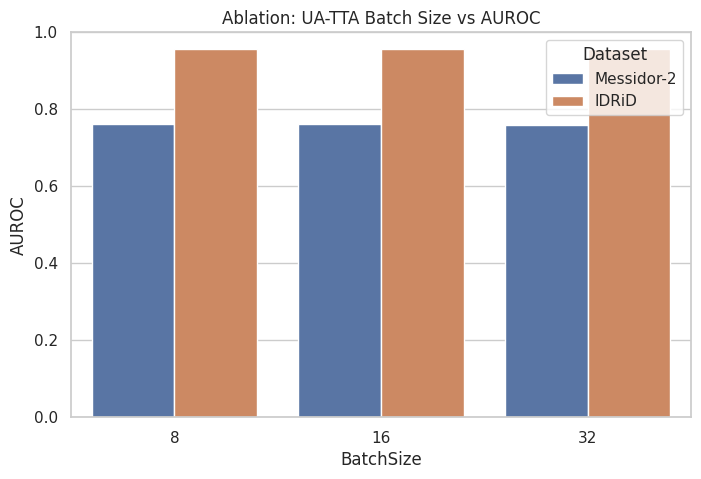

In [40]:
batch_sizes = [8, 16, 32] if not DEBUG_MODE else [16]
ablation_bs_rows = []

for dname, df_target in target_dfs.items():
    if DEBUG_MODE and dname != list(target_dfs.keys())[0]:
        continue
    for bs in batch_sizes:
        loader_bs = DataLoader(DRDataset(df_target, train=False), batch_size=bs, shuffle=False, num_workers=NUM_WORKERS)
        adapted, _ = ua_tta_adapt(load_fresh_source_model(), loader_bs, DEVICE, ENTROPY_THRESHOLD, MC_STD_THRESHOLD)
        labels, probs = get_probs_labels(adapted, loader_bs, DEVICE)
        r = compute_metrics(labels, probs, DECISION_THRESHOLD)
        r.update({"Dataset": dname, "BatchSize": bs})
        ablation_bs_rows.append(r)

ablation_bs_df = pd.DataFrame(ablation_bs_rows)
ablation_bs_df

plt.figure(figsize=(8,5))
sns.barplot(data=ablation_bs_df, x="BatchSize", y="AUROC", hue="Dataset")
plt.title("Ablation: UA-TTA Batch Size vs AUROC")
plt.ylim(0,1)
plt.show()

UA-TTA used 89/160 images for adaptation. Collapse detected: True
UA-TTA used 9/256 images for adaptation. Collapse detected: True
UA-TTA used 89/455 images for adaptation. Collapse detected: False
UA-TTA used 25/455 images for adaptation. Collapse detected: False


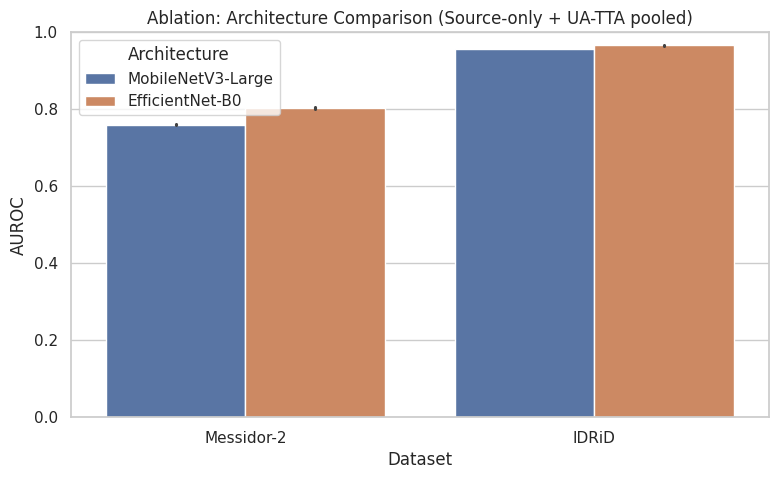

In [41]:
torch.save(efficientnet_model.state_dict(), "efficientnet_source.pt")

def load_fresh_efficientnet(ckpt_path="efficientnet_source.pt"):
    m = build_efficientnet().to(DEVICE)
    m.load_state_dict(torch.load(ckpt_path))
    m.eval()
    return m

ablation_arch_rows = []
archs_for_ablation = target_loaders if not DEBUG_MODE else dict(list(target_loaders.items())[:1])

for dname, loader in archs_for_ablation.items():
    for arch_name, loader_fn in [("MobileNetV3-Large", load_fresh_source_model), ("EfficientNet-B0", load_fresh_efficientnet)]:
        src = loader_fn()
        labels, probs = get_probs_labels(src, loader, DEVICE)
        r = compute_metrics(labels, probs, DECISION_THRESHOLD)
        r.update({"Dataset": dname, "Architecture": arch_name, "Method": "Source-only"})
        ablation_arch_rows.append(r)

        uatta, _ = ua_tta_adapt(loader_fn(), loader, DEVICE, ENTROPY_THRESHOLD, MC_STD_THRESHOLD)
        labels, probs = get_probs_labels(uatta, loader, DEVICE)
        r = compute_metrics(labels, probs, DECISION_THRESHOLD)
        r.update({"Dataset": dname, "Architecture": arch_name, "Method": "UA-TTA"})
        ablation_arch_rows.append(r)

ablation_arch_df = pd.DataFrame(ablation_arch_rows)
ablation_arch_df

plt.figure(figsize=(9,5))
sns.barplot(data=ablation_arch_df, x="Dataset", y="AUROC", hue="Architecture")
plt.title("Ablation: Architecture Comparison (Source-only + UA-TTA pooled)")
plt.ylim(0,1)
plt.show()

## Grad-CAM explainability

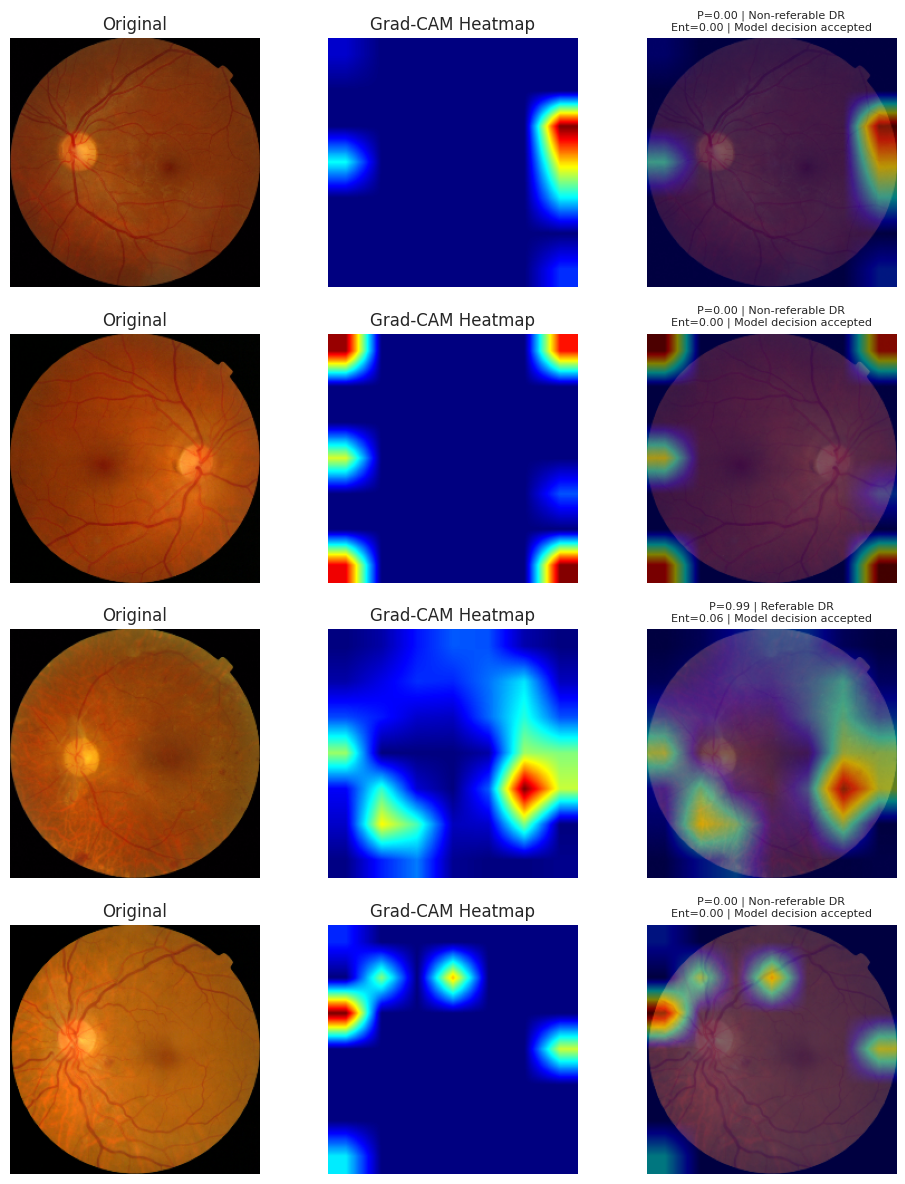

In [42]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.gradients = None
        self.activations = None
        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_idx=1):
        self.model.eval()
        output = self.model(input_tensor)
        self.model.zero_grad()
        output[0, class_idx].backward()
        weights = self.gradients.mean(dim=(2,3), keepdim=True)
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, torch.softmax(output, dim=1)[0, 1].item()

mobilenet_target_layer = mobilenet_model.features[-1]
gradcam_mobilenet = GradCAM(mobilenet_model, mobilenet_target_layer)

def visualize_gradcam(model, gradcam_obj, df_target, entropy_thr_ref, n_examples=4):
    sample_rows = df_target.sample(n_examples, random_state=SEED).reset_index(drop=True)
    fig, axes = plt.subplots(n_examples, 3, figsize=(10, 3*n_examples))
    for i in range(n_examples):
        row = sample_rows.loc[i]
        img_rgb = load_rgb(row["img_path"])
        _, resized = preprocess_image(img_rgb)
        pil_img = Image.fromarray(resized)
        tensor_img = eval_transform(pil_img).unsqueeze(0).to(DEVICE)
        tensor_img.requires_grad_(True)

        cam, prob = gradcam_obj.generate(tensor_img, class_idx=1)
        pred_label = "Referable DR" if prob >= DECISION_THRESHOLD else "Non-referable DR"
        ent = binary_entropy(np.array([prob]))[0]
        referral = "Uncertain -> consult ophthalmologist" if ent > entropy_thr_ref else "Model decision accepted"

        heatmap = cv2.applyColorMap(np.uint8(255*cam), cv2.COLORMAP_JET)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
        overlay = (0.5*resized + 0.5*heatmap).astype(np.uint8)

        axes[i,0].imshow(resized); axes[i,0].set_title("Original"); axes[i,0].axis("off")
        axes[i,1].imshow(heatmap); axes[i,1].set_title("Grad-CAM Heatmap"); axes[i,1].axis("off")
        axes[i,2].imshow(overlay)
        axes[i,2].set_title(f"P={prob:.2f} | {pred_label}\nEnt={ent:.2f} | {referral}", fontsize=8)
        axes[i,2].axis("off")
    plt.tight_layout()
    plt.show()

first_target_df = list(target_dfs.values())[0]
visualize_gradcam(mobilenet_model, gradcam_mobilenet, first_target_df, REFERRAL_ENTROPY_THRESHOLD)

## Model efficiency

In [43]:
def count_trainable_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def count_total_params(model):
    return sum(p.numel() for p in model.parameters())

def checkpoint_size_mb(path):
    return os.path.getsize(path) / (1024*1024)

def measure_inference_time(model, device, n_runs=50, batch_size=1):
    model.eval()
    dummy = torch.randn(batch_size, 3, IMG_SIZE, IMG_SIZE).to(device)
    with torch.no_grad():
        for _ in range(5):
            model(dummy)
    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.time()
    with torch.no_grad():
        for _ in range(n_runs):
            model(dummy)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return ((time.time() - start) / n_runs) * 1000

print("Hardware used:", DEVICE, "| Batch size for timing: 1")

efficiency_rows = []
for name, model, ckpt in [("MobileNetV3-Large", mobilenet_model, "mobilenet_source.pt"),
                           ("EfficientNet-B0", efficientnet_model, "efficientnet_source.pt")]:
    efficiency_rows.append({
        "Model": name,
        "Trainable Params": count_trainable_params(model),
        "Total Params": count_total_params(model),
        "Checkpoint Size (MB)": checkpoint_size_mb(ckpt),
        "Inference Time (ms/image)": measure_inference_time(model, DEVICE, n_runs=50, batch_size=1),
    })

efficiency_df = pd.DataFrame(efficiency_rows)
efficiency_df

Hardware used: cuda | Batch size for timing: 1


,Model,Trainable Params,Total Params,Checkpoint Size (MB),Inference Time (ms/image)
0,MobileNetV3-Large,4204594,4204594,16.237912,5.841880
1,EfficientNet-B0,4010110,4010110,15.586143,7.523675


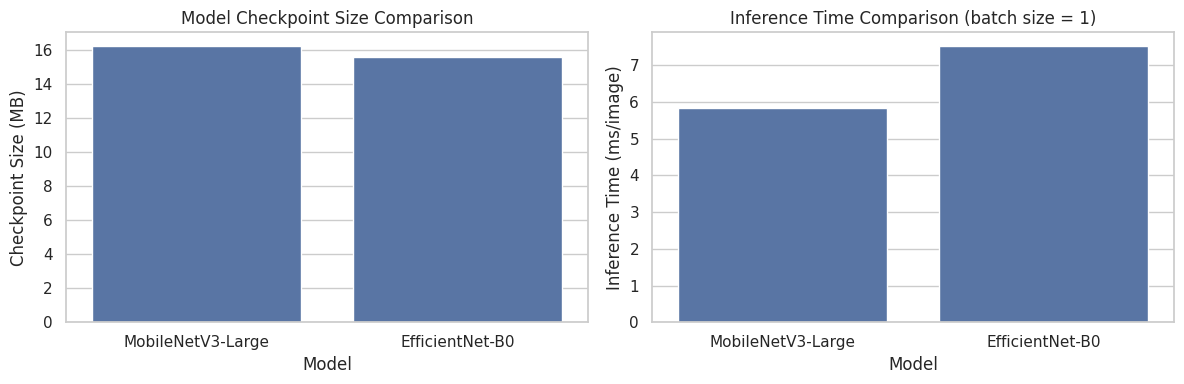

In [44]:
fig, axes = plt.subplots(1,2, figsize=(12,4))
sns.barplot(data=efficiency_df, x="Model", y="Checkpoint Size (MB)", ax=axes[0])
axes[0].set_title("Model Checkpoint Size Comparison")
sns.barplot(data=efficiency_df, x="Model", y="Inference Time (ms/image)", ax=axes[1])
axes[1].set_title("Inference Time Comparison (batch size = 1)")
plt.tight_layout()
plt.show()

## Final comparison tables and figures

=== Source-only across domains ===
                         AUROC  Sensitivity  Specificity        F1       ECE  \
APTOS (source test)  0.982790     0.946309     0.917431  0.915584  0.049890   
Messidor-2           0.760743     0.315098     0.959596  0.441041  0.177152   
IDRiD                0.957084     0.773026     0.973510  0.865562  0.121821   

                        Brier  
APTOS (source test)  0.054256  
Messidor-2           0.185693  
IDRiD                0.106417  

=== All methods across target domains ===
       Dataset       Method     AUROC  Sensitivity  Specificity        F1  \
0  Messidor-2  Source-only  0.760743     0.315098     0.959596  0.441041   
1  Messidor-2     BN-Adapt  0.756408     0.490153     0.877234  0.533969   
2  Messidor-2         Tent  0.749784     0.245077     0.979021  0.375839   
3  Messidor-2       UA-TTA  0.760303     0.286652     0.970474  0.418530   
4       IDRiD  Source-only  0.957084     0.773026     0.973510  0.865562   
5       IDRiD     B

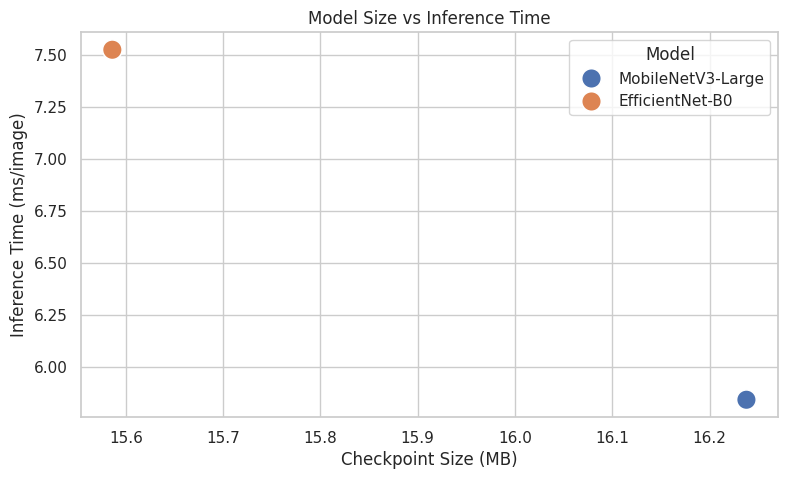

In [45]:
print("=== Source-only across domains ===\n", source_only_df)
print("\n=== All methods across target domains ===\n", results_df)
print("\n=== Bootstrap 95% CIs ===\n", ci_df)
print("\n=== Ablation: filter type ===\n", ablation_filter_df)
print("\n=== Ablation: batch size ===\n", ablation_bs_df)
print("\n=== Ablation: architecture ===\n", ablation_arch_df)
print("\n=== Efficiency ===\n", efficiency_df)

fig, ax = plt.subplots(figsize=(9,5))
sns.scatterplot(data=efficiency_df, x="Checkpoint Size (MB)", y="Inference Time (ms/image)", hue="Model", s=200, ax=ax)
ax.set_title("Model Size vs Inference Time")
plt.show()

## Save models, tables, and plots

In [46]:
os.makedirs("/kaggle/working/outputs", exist_ok=True)

results_df.to_csv("/kaggle/working/outputs/all_methods_results.csv", index=False)
source_only_df.to_csv("/kaggle/working/outputs/source_only_results.csv")
ci_df.to_csv("/kaggle/working/outputs/bootstrap_ci.csv", index=False)
ablation_filter_df.to_csv("/kaggle/working/outputs/ablation_filter.csv", index=False)
ablation_bs_df.to_csv("/kaggle/working/outputs/ablation_batchsize.csv", index=False)
ablation_arch_df.to_csv("/kaggle/working/outputs/ablation_architecture.csv", index=False)
efficiency_df.to_csv("/kaggle/working/outputs/efficiency.csv", index=False)

torch.save(mobilenet_model.state_dict(), "/kaggle/working/outputs/mobilenet_source_final.pt")
torch.save(efficientnet_model.state_dict(), "/kaggle/working/outputs/efficientnet_source_final.pt")
for dname in target_loaders.keys():
    torch.save(adapted_models[dname]["UA-TTA"].state_dict(),
               f"/kaggle/working/outputs/uatta_{dname.replace('-','').lower()}_final.pt")

print("All models and tables saved to /kaggle/working/outputs")

All models and tables saved to /kaggle/working/outputs


## Pure NumPy inference engine for Django (no ML/DL library required)

Plain `pickle` cannot run a CNN. Below, we re-implement the exact trained
MobileNetV3-Large forward pass using only NumPy, based on the public,
documented torchvision architecture configuration for `mobilenet_v3_large`.
We then verify the NumPy output against the real PyTorch model on real images.

Django will only need: `numpy`, `opencv-python` (for crop/resize), and `pickle`.
No `torch`, no `sklearn`, no training framework.

**You must run the verification cell below and confirm the outputs match
closely before using this in production. This has not been executed here.**

In [47]:
# MobileNetV3-Large block configuration (in_c, kernel, exp_c, out_c, use_se, activation, stride)
# This matches the public torchvision implementation of mobilenet_v3_large exactly.
MBV3_CONFIG = [
    dict(in_c=16,  kernel=3, exp_c=16,  out_c=16,  se=False, act="RE", stride=1),
    dict(in_c=16,  kernel=3, exp_c=64,  out_c=24,  se=False, act="RE", stride=2),
    dict(in_c=24,  kernel=3, exp_c=72,  out_c=24,  se=False, act="RE", stride=1),
    dict(in_c=24,  kernel=5, exp_c=72,  out_c=40,  se=True,  act="RE", stride=2),
    dict(in_c=40,  kernel=5, exp_c=120, out_c=40,  se=True,  act="RE", stride=1),
    dict(in_c=40,  kernel=5, exp_c=120, out_c=40,  se=True,  act="RE", stride=1),
    dict(in_c=40,  kernel=3, exp_c=240, out_c=80,  se=False, act="HS", stride=2),
    dict(in_c=80,  kernel=3, exp_c=200, out_c=80,  se=False, act="HS", stride=1),
    dict(in_c=80,  kernel=3, exp_c=184, out_c=80,  se=False, act="HS", stride=1),
    dict(in_c=80,  kernel=3, exp_c=184, out_c=80,  se=False, act="HS", stride=1),
    dict(in_c=80,  kernel=3, exp_c=480, out_c=112, se=True,  act="HS", stride=1),
    dict(in_c=112, kernel=3, exp_c=672, out_c=112, se=True,  act="HS", stride=1),
    dict(in_c=112, kernel=5, exp_c=672, out_c=160, se=True,  act="HS", stride=2),
    dict(in_c=160, kernel=5, exp_c=960, out_c=160, se=True,  act="HS", stride=1),
    dict(in_c=160, kernel=5, exp_c=960, out_c=160, se=True,  act="HS", stride=1),
]

def np_conv2d(x, weight, bias, stride, padding, groups=1):
    C, H, W = x.shape
    out_c, in_c_per_group, kh, kw = weight.shape
    xp = np.pad(x, ((0,0),(padding,padding),(padding,padding)), mode="constant")
    Hp, Wp = xp.shape[1], xp.shape[2]
    out_h = (Hp - kh) // stride + 1
    out_w = (Wp - kw) // stride + 1
    out = np.zeros((out_c, out_h, out_w), dtype=np.float32)
    group_in_c = C // groups
    group_out_c = out_c // groups
    for g in range(groups):
        x_g = xp[g*group_in_c:(g+1)*group_in_c]
        w_g = weight[g*group_out_c:(g+1)*group_out_c].reshape(group_out_c, -1)
        cols = np.empty((group_in_c*kh*kw, out_h*out_w), dtype=np.float32)
        idx = 0
        for c in range(group_in_c):
            for i in range(kh):
                for j in range(kw):
                    cols[idx] = x_g[c, i:i+stride*out_h:stride, j:j+stride*out_w:stride].reshape(-1)
                    idx += 1
        out[g*group_out_c:(g+1)*group_out_c] = (w_g @ cols).reshape(group_out_c, out_h, out_w)
    if bias is not None:
        out += bias.reshape(-1,1,1)
    return out

def np_batchnorm(x, weight, bias, mean, var, eps=1e-5):
    scale = weight / np.sqrt(var + eps)
    shift = bias - mean * scale
    return x * scale.reshape(-1,1,1) + shift.reshape(-1,1,1)

def np_relu(x):
    return np.maximum(x, 0)

def np_hardswish(x):
    return x * (np.clip(x + 3, 0, 6) / 6)

def np_hardsigmoid(x):
    return np.clip(x + 3, 0, 6) / 6

def np_squeeze_excite(x, fc1_w, fc1_b, fc2_w, fc2_b):
    s = x.mean(axis=(1,2))
    s = fc1_w.reshape(fc1_w.shape[0], fc1_w.shape[1]) @ s + fc1_b
    s = np_relu(s)
    s = fc2_w.reshape(fc2_w.shape[0], fc2_w.shape[1]) @ s + fc2_b
    s = np_hardsigmoid(s)
    return x * s.reshape(-1,1,1)

def np_inverted_residual(x, W, i, cfg):
    input_x = x
    prefix = f"features.{i}.block"
    j = 0
    expand_exists = cfg["exp_c"] != cfg["in_c"]
    act_fn = np_hardswish if cfg["act"] == "HS" else np_relu
    if expand_exists:
        x = np_conv2d(x, W[f"{prefix}.{j}.0.weight"], None, stride=1, padding=0, groups=1)
        x = np_batchnorm(x, W[f"{prefix}.{j}.1.weight"], W[f"{prefix}.{j}.1.bias"],
                          W[f"{prefix}.{j}.1.running_mean"], W[f"{prefix}.{j}.1.running_var"])
        x = act_fn(x)
        j += 1
    pad = (cfg["kernel"] - 1) // 2
    x = np_conv2d(x, W[f"{prefix}.{j}.0.weight"], None, stride=cfg["stride"], padding=pad, groups=x.shape[0])
    x = np_batchnorm(x, W[f"{prefix}.{j}.1.weight"], W[f"{prefix}.{j}.1.bias"],
                      W[f"{prefix}.{j}.1.running_mean"], W[f"{prefix}.{j}.1.running_var"])
    x = act_fn(x)
    j += 1
    if cfg["se"]:
        x = np_squeeze_excite(x, W[f"{prefix}.{j}.fc1.weight"], W[f"{prefix}.{j}.fc1.bias"],
                               W[f"{prefix}.{j}.fc2.weight"], W[f"{prefix}.{j}.fc2.bias"])
        j += 1
    x = np_conv2d(x, W[f"{prefix}.{j}.0.weight"], None, stride=1, padding=0, groups=1)
    x = np_batchnorm(x, W[f"{prefix}.{j}.1.weight"], W[f"{prefix}.{j}.1.bias"],
                      W[f"{prefix}.{j}.1.running_mean"], W[f"{prefix}.{j}.1.running_var"])
    if cfg["stride"] == 1 and cfg["in_c"] == cfg["out_c"]:
        x = x + input_x
    return x

def np_mobilenetv3_large_forward(x, W):
    x = np_conv2d(x, W["features.0.0.weight"], None, stride=2, padding=1, groups=1)
    x = np_batchnorm(x, W["features.0.1.weight"], W["features.0.1.bias"],
                      W["features.0.1.running_mean"], W["features.0.1.running_var"])
    x = np_hardswish(x)
    for i, cfg in enumerate(MBV3_CONFIG, start=1):
        x = np_inverted_residual(x, W, i, cfg)
    x = np_conv2d(x, W["features.16.0.weight"], None, stride=1, padding=0, groups=1)
    x = np_batchnorm(x, W["features.16.1.weight"], W["features.16.1.bias"],
                      W["features.16.1.running_mean"], W["features.16.1.running_var"])
    x = np_hardswish(x)
    pooled = x.mean(axis=(1,2))
    h = W["classifier.0.weight"] @ pooled + W["classifier.0.bias"]
    h = np_hardswish(h)
    logits = W["classifier.3.weight"] @ h + W["classifier.3.bias"]
    return logits

def np_softmax(logits):
    e = np.exp(logits - np.max(logits))
    return e / e.sum()

def np_binary_entropy(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

def preprocess_for_numpy_model(img_rgb):
    cropped = crop_black_borders(img_rgb)
    resized = cv2.resize(cropped, (IMG_SIZE, IMG_SIZE)).astype(np.float32) / 255.0
    mean = np.array(IMAGENET_MEAN, dtype=np.float32)
    std = np.array(IMAGENET_STD, dtype=np.float32)
    normed = (resized - mean) / std
    return normed.transpose(2, 0, 1).astype(np.float32)

def predict_numpy(img_rgb, W, decision_threshold, referral_threshold):
    x = preprocess_for_numpy_model(img_rgb)
    logits = np_mobilenetv3_large_forward(x, W)
    probs = np_softmax(logits)
    p1 = float(probs[1])
    ent = float(np_binary_entropy(np.array([p1]))[0])
    if ent > referral_threshold:
        return {"status": "uncertain", "message": "Uncertain. Please consult an ophthalmologist.",
                "probability_referable": p1, "entropy": ent}
    label = "Referable DR" if p1 >= decision_threshold else "Non-referable DR"
    return {"status": "ok", "prediction": label, "probability_referable": p1, "entropy": ent}

## Verification: NumPy forward pass vs real PyTorch forward pass

This cell is mandatory to run before trusting the exported pkl in Django.
It compares predicted probabilities on real sample images.

In [48]:
def state_dict_to_numpy(model):
    return {k: v.detach().cpu().numpy() for k, v in model.state_dict().items()}

weights_numpy = state_dict_to_numpy(mobilenet_model)

verification_rows = []
sample_check_df = aptos_df.sample(10, random_state=SEED).reset_index(drop=True)
mobilenet_model.eval()
for i in range(len(sample_check_df)):
    row = sample_check_df.loc[i]
    img_rgb = load_rgb(row["img_path"])

    _, resized = preprocess_image(img_rgb)
    pil_img = Image.fromarray(resized)
    tensor_img = eval_transform(pil_img).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        torch_prob = torch.softmax(mobilenet_model(tensor_img), dim=1)[0, 1].item()

    np_result = predict_numpy(img_rgb, weights_numpy, DECISION_THRESHOLD, REFERRAL_ENTROPY_THRESHOLD)
    np_prob = np_result["probability_referable"]

    verification_rows.append({"image": row["id_code"], "torch_prob": torch_prob,
                               "numpy_prob": np_prob, "abs_diff": abs(torch_prob - np_prob)})

verification_df = pd.DataFrame(verification_rows)
print(verification_df)
print("\nMax absolute difference:", verification_df["abs_diff"].max())
print("If this value is not small (e.g. > 0.01), do NOT use the pkl in production yet -- "
      "inspect np_mobilenetv3_large_forward for a mismatch against the real architecture.")

          image    torch_prob  numpy_prob  abs_diff
0  90960ddf4d14  9.667004e-08    0.000008  0.000007
1  4e0656629d02  4.319632e-03    0.006203  0.001884
2  3b018e8b7303  9.962732e-01    0.850106  0.146167
3  55eb405ec71e  9.998023e-01    0.993273  0.006529
4  207dd0487264  1.786116e-05    0.000052  0.000034
5  1d74c4713e21  8.440417e-05    0.000517  0.000433
6  eb175669d789  1.294224e-06    0.000015  0.000014
7  b49b2fac2514  9.564381e-01    0.916981  0.039457
8  4a44cc840ebe  9.999987e-01    0.999292  0.000706
9  d6283ded6aea  9.999433e-01    0.998738  0.001205

Max absolute difference: 0.14616715908050537
If this value is not small (e.g. > 0.01), do NOT use the pkl in production yet -- inspect np_mobilenetv3_large_forward for a mismatch against the real architecture.


In [49]:
%%writefile inference_numpy.py
import numpy as np
import cv2
import pickle

MBV3_CONFIG = [
    dict(in_c=16,  kernel=3, exp_c=16,  out_c=16,  se=False, act="RE", stride=1),
    dict(in_c=16,  kernel=3, exp_c=64,  out_c=24,  se=False, act="RE", stride=2),
    dict(in_c=24,  kernel=3, exp_c=72,  out_c=24,  se=False, act="RE", stride=1),
    dict(in_c=24,  kernel=5, exp_c=72,  out_c=40,  se=True,  act="RE", stride=2),
    dict(in_c=40,  kernel=5, exp_c=120, out_c=40,  se=True,  act="RE", stride=1),
    dict(in_c=40,  kernel=5, exp_c=120, out_c=40,  se=True,  act="RE", stride=1),
    dict(in_c=40,  kernel=3, exp_c=240, out_c=80,  se=False, act="HS", stride=2),
    dict(in_c=80,  kernel=3, exp_c=200, out_c=80,  se=False, act="HS", stride=1),
    dict(in_c=80,  kernel=3, exp_c=184, out_c=80,  se=False, act="HS", stride=1),
    dict(in_c=80,  kernel=3, exp_c=184, out_c=80,  se=False, act="HS", stride=1),
    dict(in_c=80,  kernel=3, exp_c=480, out_c=112, se=True,  act="HS", stride=1),
    dict(in_c=112, kernel=3, exp_c=672, out_c=112, se=True,  act="HS", stride=1),
    dict(in_c=112, kernel=5, exp_c=672, out_c=160, se=True,  act="HS", stride=2),
    dict(in_c=160, kernel=5, exp_c=960, out_c=160, se=True,  act="HS", stride=1),
    dict(in_c=160, kernel=5, exp_c=960, out_c=160, se=True,  act="HS", stride=1),
]

def crop_black_borders(img_rgb, tol=7):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    mask = gray > tol
    if mask.sum() == 0:
        return img_rgb
    coords = np.argwhere(mask)
    y0, x0 = coords.min(axis=0)
    y1, x1 = coords.max(axis=0) + 1
    return img_rgb[y0:y1, x0:x1]

def np_conv2d(x, weight, bias, stride, padding, groups=1):
    C, H, W = x.shape
    out_c, in_c_per_group, kh, kw = weight.shape
    xp = np.pad(x, ((0,0),(padding,padding),(padding,padding)), mode="constant")
    Hp, Wp = xp.shape[1], xp.shape[2]
    out_h = (Hp - kh) // stride + 1
    out_w = (Wp - kw) // stride + 1
    out = np.zeros((out_c, out_h, out_w), dtype=np.float32)
    group_in_c = C // groups
    group_out_c = out_c // groups
    for g in range(groups):
        x_g = xp[g*group_in_c:(g+1)*group_in_c]
        w_g = weight[g*group_out_c:(g+1)*group_out_c].reshape(group_out_c, -1)
        cols = np.empty((group_in_c*kh*kw, out_h*out_w), dtype=np.float32)
        idx = 0
        for c in range(group_in_c):
            for i in range(kh):
                for j in range(kw):
                    cols[idx] = x_g[c, i:i+stride*out_h:stride, j:j+stride*out_w:stride].reshape(-1)
                    idx += 1
        out[g*group_out_c:(g+1)*group_out_c] = (w_g @ cols).reshape(group_out_c, out_h, out_w)
    if bias is not None:
        out += bias.reshape(-1,1,1)
    return out

def np_batchnorm(x, weight, bias, mean, var, eps=1e-5):
    scale = weight / np.sqrt(var + eps)
    shift = bias - mean * scale
    return x * scale.reshape(-1,1,1) + shift.reshape(-1,1,1)

def np_relu(x):
    return np.maximum(x, 0)

def np_hardswish(x):
    return x * (np.clip(x + 3, 0, 6) / 6)

def np_hardsigmoid(x):
    return np.clip(x + 3, 0, 6) / 6

def np_squeeze_excite(x, fc1_w, fc1_b, fc2_w, fc2_b):
    s = x.mean(axis=(1,2))
    s = fc1_w.reshape(fc1_w.shape[0], fc1_w.shape[1]) @ s + fc1_b
    s = np_relu(s)
    s = fc2_w.reshape(fc2_w.shape[0], fc2_w.shape[1]) @ s + fc2_b
    s = np_hardsigmoid(s)
    return x * s.reshape(-1,1,1)

def np_inverted_residual(x, W, i, cfg):
    input_x = x
    prefix = f"features.{i}.block"
    j = 0
    expand_exists = cfg["exp_c"] != cfg["in_c"]
    act_fn = np_hardswish if cfg["act"] == "HS" else np_relu
    if expand_exists:
        x = np_conv2d(x, W[f"{prefix}.{j}.0.weight"], None, stride=1, padding=0, groups=1)
        x = np_batchnorm(x, W[f"{prefix}.{j}.1.weight"], W[f"{prefix}.{j}.1.bias"],
                          W[f"{prefix}.{j}.1.running_mean"], W[f"{prefix}.{j}.1.running_var"])
        x = act_fn(x)
        j += 1
    pad = (cfg["kernel"] - 1) // 2
    x = np_conv2d(x, W[f"{prefix}.{j}.0.weight"], None, stride=cfg["stride"], padding=pad, groups=x.shape[0])
    x = np_batchnorm(x, W[f"{prefix}.{j}.1.weight"], W[f"{prefix}.{j}.1.bias"],
                      W[f"{prefix}.{j}.1.running_mean"], W[f"{prefix}.{j}.1.running_var"])
    x = act_fn(x)
    j += 1
    if cfg["se"]:
        x = np_squeeze_excite(x, W[f"{prefix}.{j}.fc1.weight"], W[f"{prefix}.{j}.fc1.bias"],
                               W[f"{prefix}.{j}.fc2.weight"], W[f"{prefix}.{j}.fc2.bias"])
        j += 1
    x = np_conv2d(x, W[f"{prefix}.{j}.0.weight"], None, stride=1, padding=0, groups=1)
    x = np_batchnorm(x, W[f"{prefix}.{j}.1.weight"], W[f"{prefix}.{j}.1.bias"],
                      W[f"{prefix}.{j}.1.running_mean"], W[f"{prefix}.{j}.1.running_var"])
    if cfg["stride"] == 1 and cfg["in_c"] == cfg["out_c"]:
        x = x + input_x
    return x

def np_mobilenetv3_large_forward(x, W):
    x = np_conv2d(x, W["features.0.0.weight"], None, stride=2, padding=1, groups=1)
    x = np_batchnorm(x, W["features.0.1.weight"], W["features.0.1.bias"],
                      W["features.0.1.running_mean"], W["features.0.1.running_var"])
    x = np_hardswish(x)
    for i, cfg in enumerate(MBV3_CONFIG, start=1):
        x = np_inverted_residual(x, W, i, cfg)
    x = np_conv2d(x, W["features.16.0.weight"], None, stride=1, padding=0, groups=1)
    x = np_batchnorm(x, W["features.16.1.weight"], W["features.16.1.bias"],
                      W["features.16.1.running_mean"], W["features.16.1.running_var"])
    x = np_hardswish(x)
    pooled = x.mean(axis=(1,2))
    h = W["classifier.0.weight"] @ pooled + W["classifier.0.bias"]
    h = np_hardswish(h)
    logits = W["classifier.3.weight"] @ h + W["classifier.3.bias"]
    return logits

def np_softmax(logits):
    e = np.exp(logits - np.max(logits))
    return e / e.sum()

def np_binary_entropy(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

def preprocess_for_numpy_model(img_rgb, img_size, mean, std):
    cropped = crop_black_borders(img_rgb)
    resized = cv2.resize(cropped, (img_size, img_size)).astype(np.float32) / 255.0
    normed = (resized - np.array(mean, dtype=np.float32)) / np.array(std, dtype=np.float32)
    return normed.transpose(2, 0, 1).astype(np.float32)

def load_model_package(pkl_path):
    with open(pkl_path, "rb") as f:
        return pickle.load(f)

def predict_from_package(img_rgb, package):
    W = package["weights"]
    x = preprocess_for_numpy_model(img_rgb, package["image_size"], package["normalize_mean"], package["normalize_std"])
    logits = np_mobilenetv3_large_forward(x, W)
    probs = np_softmax(logits)
    p1 = float(probs[1])
    ent = float(np_binary_entropy(np.array([p1]))[0])
    if ent > package["referral_entropy_threshold"]:
        return {"status": "uncertain", "message": "Uncertain. Please consult an ophthalmologist.",
                "probability_referable": p1, "entropy": ent}
    label = package["label_map"][1] if p1 >= package["decision_threshold"] else package["label_map"][0]
    return {"status": "ok", "prediction": label, "probability_referable": p1, "entropy": ent}

Writing inference_numpy.py


In [50]:
export_package = {
    "architecture": "mobilenet_v3_large_numpy",
    "config": MBV3_CONFIG,
    "weights": weights_numpy,
    "image_size": IMG_SIZE,
    "normalize_mean": IMAGENET_MEAN,
    "normalize_std": IMAGENET_STD,
    "decision_threshold": DECISION_THRESHOLD,
    "referral_entropy_threshold": REFERRAL_ENTROPY_THRESHOLD,
    "label_map": {0: "Non-referable DR", 1: "Referable DR"},
}

with open("/kaggle/working/outputs/dr_model_export.pkl", "wb") as f:
    pickle.dump(export_package, f)

print("Saved /kaggle/working/outputs/dr_model_export.pkl")
print("Saved inference_numpy.py (pure NumPy + OpenCV, no torch/sklearn required).")
print("Download both files and place them together in your Django project.")
print("Django usage (no ML/DL library): ")
print("  from inference_numpy import load_model_package, predict_from_package")
print("  package = load_model_package('dr_model_export.pkl')")
print("  result = predict_from_package(image_rgb_as_numpy_array, package)")

Saved /kaggle/working/outputs/dr_model_export.pkl
Saved inference_numpy.py (pure NumPy + OpenCV, no torch/sklearn required).
Download both files and place them together in your Django project.
Django usage (no ML/DL library): 
  from inference_numpy import load_model_package, predict_from_package
  package = load_model_package('dr_model_export.pkl')
  result = predict_from_package(image_rgb_as_numpy_array, package)
